<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/HybridQNN_AdversarialBotnetDGA_Suryotrisongko2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adversarial robustness of a hybrid quantum-classical network for botnet DGA detection: Suryotrisongko et al. (2022) step by step

> H. Suryotrisongko, Y. Musashi, A. Tsuneda and K. Sugitani, "Adversarial Robustness in Hybrid Quantum-Classical Deep Learning for Botnet DGA Detection",
> *Journal of Information Processing* 30 (2022) 636-644. https://doi.org/10.2197/ipsjjip.30.636

**What this notebook does.** A botnet hides its command-and-control servers behind domain names produced by a *domain generation algorithm (DGA)*. The paper trains a small
*hybrid* network (a Keras network with one PennyLane quantum layer inside) to tell DGA domains from benign ones, attacks it with three *adversarial example* attacks
(FGSM, PGD, BIM), hardens it with *adversarial training*, and proposes to measure robustness by repeating the attack for 18 different attack strengths and comparing the
averages with a t-test. It does this for two quantum circuits (BasicEntanglerLayers, RandomLayers) under the simulated noise of four IBM quantum computers
(ibmq_belem, lima, quito, santiago). We rebuild every one of those experiments, add classical baselines that are attacked and hardened with **exactly the same budget**,
and add an **adaptive-attack audit** (exact-gradient margin attack with restarts, gradient-free black-box search, transfer attack) that tells us whether the robustness numbers
are real or a side effect of weak attacks ("gradient masking").

**How to run it.** Open it in Colab (badge above), choose a *CPU* runtime and use *Runtime -> Run all*. The data are downloaded automatically (380 kB). The
outputs stored in this notebook come from the **full run** (`FAST_MODE = False`: the paper's 100 epochs, all four noise models, ART's 100 attack iterations, three independent repetitions;
about 100 minutes on a shared 8-core CPU, of which 83 minutes are training). Set `FAST_MODE = True` in the configuration cell for a class demo (30 epochs, one seed, two noise models; about 6-11 minutes).

**What you get at the end.** The paper's Tables 1-6 re-computed with our code (side by side with the paper's numbers, typed in from its PDF), the robustness plots of its Figs. 5-7, the
statistics of Section 4.4, a validated noisy-circuit simulator, the adaptive-attack audit, and a table that says for every claim whether we *reproduced* it, *did not reach* it, or
*cannot check* it. Short version of what we find: see the final verdict table and the section "Reading the paper critically".

## 0. The paper in one page

**Problem.** Can a hybrid quantum-classical deep-learning DGA detector be fooled by adversarial examples, can adversarial training harden it, and how should the robustness of a
quantum model be *measured* when quantum noise makes single measurements unreliable?

**Decision.** Binary classification of a domain name (as 4 numbers): benign versus botnet DGA.

**Data.** The authors' *Botnet DGA Dataset* (IEEE DataPort, doi 10.21227/rg6z-z622, 1,803,333 domain names turned into numerical features). Four features are used: `CharLength`,
`MinREBotnets`, `TreeNewFeature`, `nGramReputation_Alexa`. n = 1,000 random samples; the confusion matrices of the paper's Table 1 add up to a **test set of 199**.

**Model (Fig. 1 and Fig. 2).** `Dense(4 -> 2, ReLU) -> Dropout -> quantum layer (2 qubits) -> Dense(2 -> 1, sigmoid)`. The quantum layer is `AngleEmbedding` followed by
`BasicEntanglerLayers` (paper's `**`) or `RandomLayers` (paper's `*`); PennyLane's Keras layer on the `qiskit.aer` device with the noise model of one IBM chip. 100 epochs, 8-19 hours per run.

**Attacks and defence.** FGSM, PGD, BIM from the Adversarial Robustness Toolbox (ART) at the default strength eps = 0.3; adversarial training = add FGSM examples (generated from the
base model) to the training data, which doubles the training and test sets (Table 3 sums to 398 test samples). **Measurement protocol:** FGSM with 18 strengths
(0.01 ... 0.9) for base and hardened model, average accuracies, unpaired t-test.

**Claims we can check.**
1. Base accuracy 85.9 / 85.1 / 84.4 % (max / average / min over the 8 experiments); the basic-entangler models are *more* accurate than the random-layer ones (Table 1).
2. At eps = 0.3 the base model loses 12.4 % accuracy on average; PGD is the worst attack (19 %, worst single case 29.1 %); the basic-entangler circuit loses 20.9 % on average and the random-layer circuit only 3.9 % (Table 2).
3. The hardened model is *more* accurate on its doubled test set (random layer 3.5 points better than basic entangler, Table 3), but its accuracy drop at eps = 0.3 is not smaller (13.8 % vs 12.4 %, Table 4).
4. Over the 18 strengths the hardened model is better than the base model in 100 % of the experiments, by 5.9 points on average, t = -4.7829 (df 283.41), "statistically significant" (Tables 5 and 6).
5. The random layer is 5.9 points better than the basic entangler over the sweep (t = -4.7793); the four noise models give the same average accuracy (74.8 / 74.8 / 74.9 / 74.9 %, pairwise p = 0.92-0.99): "hybrid models suppress quantum noise".

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | full 1.8 M-row Botnet DGA Dataset (IEEE DataPort, login needed), 4 features | the authors' public **5,001-row random sample** (Azure blob, the file used by two other papers of the repository) with the same 4 features; 1,000 rows are drawn from it as in the paper. The public file has **only the binary label** (no DGA family, no domain strings) |
| Sample / test size | n = 1,000; 199 test samples (Table 1) | n = 1,000, test fraction 0.199 -> 801 / 199; shuffled, not stratified |
| Scaling | not stated (ART needs `clip_values`) | z-scores fitted on the **training split only**, clipped to [-5, 5] (the preprocessing of the same authors' earlier paper QC-024); attacks stay inside [-5, 5], so eps = 0.3 means 0.3 standard deviations; `# CHOICE:` |
| Classical layers | Dense(4->2) ReLU, Dropout, Dense(2->1) sigmoid (Fig. 1) | the same; dropout rate 0.2 (`# CHOICE:`), Glorot-uniform weights, zero biases |
| Quantum layer | 2 qubits, AngleEmbedding + BasicEntanglerLayers / RandomLayers (Fig. 2) | the same PennyLane templates, 1 layer, RX rotations; RandomLayers with PennyLane's default seed 42 (which yields **no entangling gate**, see the circuit section); weights ~ U(-0.05, 0.05) |
| Quantum noise | `qiskit.aer` device of the PennyLane-Qiskit plug-in with the noise model of ibmq_belem / lima / quito / santiago | the calibration data of the corresponding `qiskit-ibm-runtime` fake backends turned into depolarising + thermal-relaxation + readout noise, applied by a **density-matrix simulator we wrote and validated** against PennyLane (ideal) and Qiskit Aer (noisy); exact expectation values, no shot noise |
| Training | 100 epochs, Keras, optimiser / batch size / learning rate not stated | Adam, batch 32, binary cross-entropy; learning rate chosen on a validation split of the training data from {0.003, 0.01, 0.03}; 100 epochs in the full run |
| Attacks | ART FGSM / PGD / BIM, defaults, eps = 0.3 | our PyTorch re-implementations with ART's defaults (`eps_step` 0.1, FGSM single step, BIM stops moving samples that are already misclassified, PGD without random start); exact gradients |
| Adversarial training | FGSM examples from the base model added to train and test sets (doubling) | FGSM(eps = 0.3) examples of the training set crafted against the trained base model, a **new** model trained on clean + adversarial; evaluated both on the paper's doubled test set and on the clean test set (like-for-like) |
| Repetitions | one run per configuration | `N_SEEDS` independent seeds (data split + initialisation); noise models share the seed, as in the paper (which is why its noise models give identical numbers) |
| Statistics | unpaired t-test | Welch t-test on the same 18 x configurations values |
| Extras (not in the paper) | - | classical counterparts (same network without the quantum layer and a wider MLP), random forest, SVM; adaptive-attack audit; like-for-like protocol |

**Where the paper's own numbers come from.** The tables of the PDF are vector drawings, so we typed them in (cell "paper_numbers") and checked the transcription by recomputing the
statistics the paper quotes in its text (12.4 %, 19 %, 29.1 %, 20.9 %, 3.9 %, 13.8 %, 5.9 %, t = -4.7829, df = 283.41, 74.8-74.9 %). All of them come out right.

## 1. Setup

The next cell installs pinned versions on Colab (and does nothing on a machine that already has them); the following cell holds **every tunable constant**.
`FAST_MODE = True` shrinks the budgets for a class demo: 30 epochs, one seed, two of the four noise models (belem: T-shaped chip, santiago: linear chip), 20 attack iterations (6-11 minutes).
`FAST_MODE = False` is the full budget and **the one whose outputs are stored in this notebook**: **100 epochs (the paper's), three seeds, all four noise models, ART's 100 attack iterations, 5 restarts and 300 black-box queries in the audit**.
It took about 100 minutes on a shared 8-core CPU (the paper needed 8-19 hours per single model); that is only possible because the quantum layer is evaluated through an exact multilinear shortcut that is asserted equal to the density-matrix simulator.
The paper never states the optimiser, batch size or learning rate; those are our choices, made once on a validation split of the training data.

**Gated data and tokens.** This notebook needs no Hugging Face token: the data are a small public file. (If you adapt it to a gated dataset, store the token in Colab *Secrets* under the name
`HF_TOKEN` and read it with `os.environ` or `google.colab.userdata`; never paste it into a cell.)

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib and torch.
# The pip line runs on Colab (or wherever PennyLane / Qiskit are missing); a prepared local environment is left untouched.
import importlib.util, subprocess, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in ("pennylane", "qiskit_aer", "qiskit_ibm_runtime", "torch")):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "qiskit==2.5.2", "qiskit-aer==0.17.2",
                    "qiskit-ibm-runtime==0.50.0", "scipy"], check=False)
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane, Qiskit and PyTorch already present; skipping pip install.")


PennyLane, Qiskit and PyTorch already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False     # True: class demo (a few minutes on a CPU). False: the full budget stated in the markdown above the cell.
SEED      = 42        # master seed; seed index r of the repeated runs uses SEED + r
IBM_TOKEN = ""        # not used: the paper only used simulators with the noise models of IBM devices (no hardware cell in this notebook)

# ---- data -------------------------------------------------------------------------------------------------------
DATA_DIR  = "dga_data"                                    # downloaded files are cached here (upload your own CSV here if the URL is down)
URL_5000  = "https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv"   # the authors' public 5,001-row sample of their IEEE DataPort dataset
FEATURES  = ["MinREBotnets", "CharLength", "TreeNewFeature", "nGramReputation_Alexa"]         # the four features named in the paper (Sec. 3)
N_SAMPLES = 1000      # paper: n = 1,000 randomly selected samples
TEST_FRAC = 0.199     # CHOICE: the paper's Table 1 confusion matrices add up to 199 test samples (83+11+85+20) -> 19.9 % of 1,000
CLIP      = 5.0       # CHOICE: standardise, then clip to [-5, 5] (the preprocessing of the same authors' earlier paper QC-024); this is also the valid box of the attacks

# ---- model (the paper only shows Fig. 1 and Fig. 2; everything else is our choice) -------------------------------
N_QUBITS  = 2         # paper Fig. 1: Dense(4 -> 2), Dropout, quantum layer (2 -> 2), Dense(2 -> 1); Fig. 2 draws two wires
HIDDEN    = 2
DROPOUT   = 0.2       # CHOICE: Keras default-like value; the rate is not stated
Q_INIT    = 0.05      # CHOICE: quantum weights ~ U(-0.05, 0.05), the Keras 'uniform' default that PennyLane's KerasLayer uses
Q_LAYERS  = 1         # one BasicEntanglerLayers / RandomLayers layer, as drawn in the paper's Fig. 2
RANDOM_LAYERS_SEED = 42   # PennyLane's default seed for the random gate choice of RandomLayers (structure fixed, angles trained)
BATCH     = 32        # CHOICE: Keras default batch size
LR_GRID   = [0.003, 0.01, 0.03]   # CHOICE: learning rates tried on a validation split of the TRAINING data only (Adam, Keras default is 0.001)

# ---- attacks (the paper used the Adversarial Robustness Toolbox, ART) -------------------------------------------
EPS_GRID    = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # the paper's 18 attack strengths
EPS_DEFAULT = 0.3     # ART's default attack strength, used for Tables 2 and 4 and for generating the adversarial-training examples
ART_STEP    = 0.1     # ART default eps_step of BIM and PGD

# ---- budgets ----------------------------------------------------------------------------------------------------
if FAST_MODE:
    EPOCHS    = 30       # paper: 100 epochs
    N_SEEDS   = 1        # independent repetitions (data split + initialisation); paper: one run per configuration
    DEVICES_USED = ["ibmq_belem", "ibmq_santiago"]   # FAST: one T-shaped and one linear chip; the paper used belem, lima, quito, santiago
    ITERS     = 20       # BIM / PGD iterations (ART default 100)
    STRONG_ITERS, RESTARTS, N_QUERIES = 30, 3, 100   # adaptive audit: strong PGD iterations, random restarts, black-box queries per sample
    AER_SHOTS = 4000
else:
    EPOCHS    = 100
    N_SEEDS   = 3
    DEVICES_USED = ["ibmq_belem", "ibmq_lima", "ibmq_quito", "ibmq_santiago"]
    ITERS     = 100
    STRONG_ITERS, RESTARTS, N_QUERIES = 100, 5, 300
    AER_SHOTS = 20000
print("FAST_MODE =", FAST_MODE, "| epochs", EPOCHS, "| seeds", N_SEEDS, "| devices", DEVICES_USED, "| BIM/PGD iterations", ITERS)


FAST_MODE = False | epochs 100 | seeds 3 | devices ['ibmq_belem', 'ibmq_lima', 'ibmq_quito', 'ibmq_santiago'] | BIM/PGD iterations 100


In [3]:
import os, time, random, warnings, math
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import pennylane as qml
import sklearn
import scipy
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import qiskit_ibm_runtime.fake_provider as fake_provider

warnings.filterwarnings("ignore")
torch.set_num_threads(1)                     # tiny circuits and a 2-neuron network: one thread is the fastest and keeps a shared machine usable
os.makedirs(DATA_DIR, exist_ok=True)

def seed_everything(seed):
    """Seed every random number generator the experiments touch (Python, NumPy, PyTorch)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

seed_everything(SEED)
rng = np.random.default_rng(SEED)
print("pennylane", qml.__version__, "| torch", torch.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)


pennylane 0.45.1 | torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | scipy 1.18.1 | numpy 2.5.4 | pandas 3.0.6


## 2. The data: the authors' public sample of the Botnet DGA Dataset

The full dataset sits behind an IEEE DataPort login. The authors also published a random sample of 5,001 rows on public Azure storage. Each row is one domain name already turned
into numbers (entropy, relative entropy to Alexa and to the botnet families, Jensen-Shannon "information radius", character length, a decision-tree feature, an n-gram reputation);
label 0 = benign, label 1 = DGA. We keep the four columns named in the paper. **Consequence for adversarial examples:** the attacks of the paper (and ours) perturb these numeric features, not the
characters of a domain name; a perturbed feature vector is not necessarily the feature vector of any real domain (we come back to this in the critical reading).

In [4]:
COLS = ["Entropy", "REAlexa", "MinREBotnets", "InformationRadius", "CharLength", "TreeNewFeature", "nGramReputation_Alexa", "Result"]
path5 = os.path.join(DATA_DIR, "BotnetDgaDataset_5000_newMethod.csv")
if not os.path.exists(path5):
    r = requests.get(URL_5000, timeout=120); r.raise_for_status()
    with open(path5, "wb") as f: f.write(r.content)
    print("downloaded", os.path.basename(path5), f"({len(r.content)/1e3:.0f} kB)")
else:
    print("using cached", os.path.basename(path5))
POOL = pd.read_csv(path5, encoding="utf-8-sig")          # the file starts with a byte-order mark
assert list(POOL.columns) == COLS, POOL.columns.tolist()
POOL = POOL.reset_index(drop=True)
print(f"\nPool: {POOL.shape[0]} rows x {POOL.shape[1]} columns | {POOL['Result'].mean()*100:.1f} % DGA (label 1) | "
      f"{POOL['Result'].isna().sum()} missing labels | {POOL.duplicated().sum()} duplicated rows (kept: the paper does not mention removing any)")


using cached BotnetDgaDataset_5000_newMethod.csv



Pool: 5001 rows x 8 columns | 44.8 % DGA (label 1) | 0 missing labels | 31 duplicated rows (kept: the paper does not mention removing any)


## 3. Sampling, splitting and scaling

For every seed we (1) draw n = 1,000 random rows, (2) split them with a shuffled `train_test_split` into 801 training and 199 test samples (the test size implied by the paper's Table 1),
and (3) standardise every feature (mean and standard deviation of the **training split only**) and clip to [-5, 5], as in the authors' earlier paper. The attacks are projected onto [-5, 5], the valid input box, and eps is measured in standard deviations. **At 199 test samples one sample is worth 0.5 accuracy points**, so
differences below 1-2 points are noise; this is true for the paper's own numbers as well.

In [5]:
def prepare(seed, n=None):
    """Random sample of n rows -> shuffled train/test split -> standardise (mean / std of the TRAIN split only) -> clip to [-CLIP, CLIP].
    [-CLIP, CLIP] is also the valid input box the attacks must respect (like ART's clip_values)."""
    n = n or N_SAMPLES
    r = np.random.default_rng(seed)
    d = POOL.iloc[r.choice(len(POOL), size=n, replace=False)]
    X, y = d[FEATURES].values.astype(float), d["Result"].values.astype(int)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_FRAC, random_state=seed)     # paper: shuffled split, no stratification stated
    sc = StandardScaler().fit(Xtr)                                         # CHOICE: z-scores, so eps = 0.3 means "0.3 standard deviations" for every feature
    Xtr, Xte = np.clip(sc.transform(Xtr), -CLIP, CLIP), np.clip(sc.transform(Xte), -CLIP, CLIP)
    return Xtr.astype(np.float32), Xte.astype(np.float32), ytr.astype(np.float32), yte.astype(np.float32)

Xtr, Xte, ytr, yte = prepare(SEED)
print(f"seed {SEED}: train {Xtr.shape} (DGA share {ytr.mean()*100:.1f} %), test {Xte.shape} (DGA share {yte.mean()*100:.1f} %; paper's test set: 103 DGA of 199 = 51.8 %)")
print("each test sample is worth", round(100 / len(yte), 2), "accuracy points")


seed 42: train (801, 4) (DGA share 47.1 %), test (199, 4) (DGA share 46.7 %; paper's test set: 103 DGA of 199 = 51.8 %)
each test sample is worth 0.5 accuracy points


## Dataset Exploration and Visualisation

The cells below print the shape, the feature names, the original label values and the class counts of the data we use, plot the real class distribution (bar charts), the feature
distributions by class, and a 2-D scatter in which every point is a real domain coloured by its ground-truth label (benign / DGA): first the raw PCA coordinates (PCA fitted on the
training split), then the same coordinates scaled to [0, pi], which is the range of a rotation angle in angle encoding. The two classes overlap strongly in two dimensions, which is
why a 2-qubit model reaches about 85 % and not 99 %.

Dataset (pool): (5001, 8) | columns: ['Entropy', 'REAlexa', 'MinREBotnets', 'InformationRadius', 'CharLength', 'TreeNewFeature', 'nGramReputation_Alexa', 'Result']
Features used by the paper: ['MinREBotnets', 'CharLength', 'TreeNewFeature', 'nGramReputation_Alexa']
Original label values (column 'Result'): 0 = benign (Alexa-style domain), 1 = botnet DGA domain
NOTE: the public sample carries only this binary label, not the DGA family (Cryptolocker, Conficker, Goz, ...), and not the domain strings;
      so the 'attack family' colouring asked for in the repository conventions is not possible with the public data.


,label,value,count,share %
0,benign,0,2763,55.2
1,DGA,1,2238,44.8


,count,mean,std,min,25%,50%,75%,max
MinREBotnets,5001.0,1.288,0.571,0.194,0.868,1.229,1.610,5.08
CharLength,5001.0,17.160,6.778,5.000,12.000,16.000,20.000,41.00
TreeNewFeature,5001.0,0.444,0.335,0.002,0.107,0.353,0.829,0.99
nGramReputation_Alexa,5001.0,81.337,54.066,3.557,39.435,64.663,110.882,314.29
Result,5001.0,0.448,0.497,0.000,0.000,0.000,1.000,1.00


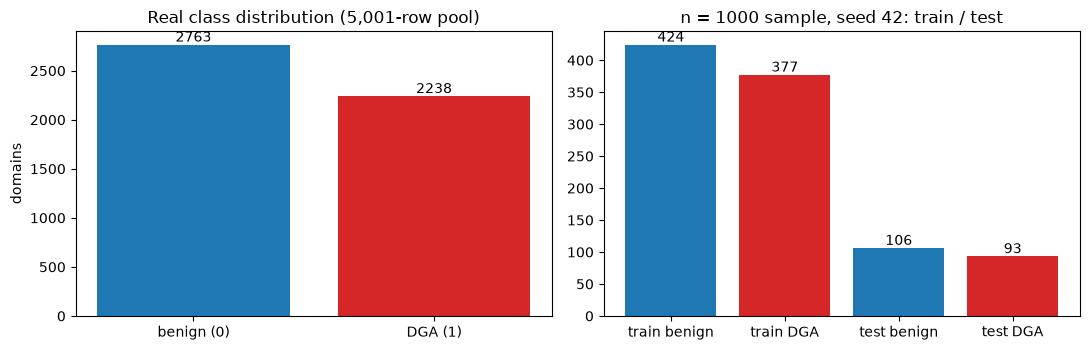

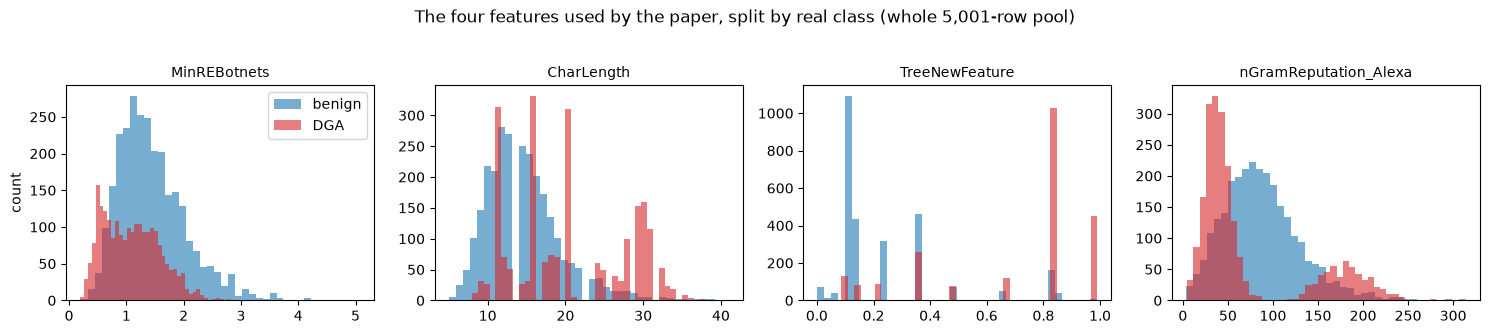

In [6]:
print("Dataset (pool):", POOL.shape, "| columns:", COLS)
print("Features used by the paper:", FEATURES)
print("Original label values (column 'Result'): 0 = benign (Alexa-style domain), 1 = botnet DGA domain")
print("NOTE: the public sample carries only this binary label, not the DGA family (Cryptolocker, Conficker, Goz, ...), and not the domain strings;")
print("      so the 'attack family' colouring asked for in the repository conventions is not possible with the public data.")
counts = POOL["Result"].value_counts().sort_index()
display(pd.DataFrame({"label": ["benign", "DGA"], "value": counts.index, "count": counts.values, "share %": (100 * counts.values / counts.sum()).round(1)}))
display(POOL[FEATURES + ["Result"]].describe().T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(["benign (0)", "DGA (1)"], counts.values, color=["tab:blue", "tab:red"]); axes[0].set_title("Real class distribution (5,001-row pool)"); axes[0].set_ylabel("domains")
for c, v in enumerate(counts.values): axes[0].text(c, v, str(v), ha="center", va="bottom")
nums = [(ytr == 0).sum(), (ytr == 1).sum(), (yte == 0).sum(), (yte == 1).sum()]
axes[1].bar(["train benign", "train DGA", "test benign", "test DGA"], nums, color=["tab:blue", "tab:red", "tab:blue", "tab:red"])
axes[1].set_title(f"n = {N_SAMPLES} sample, seed {SEED}: train / test")
for c, v in enumerate(nums): axes[1].text(c, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, f in zip(axes, FEATURES):
    for c, col, lab in [(0, "tab:blue", "benign"), (1, "tab:red", "DGA")]:
        ax.hist(POOL.loc[POOL.Result == c, f], bins=40, alpha=0.6, color=col, label=lab)
    ax.set_title(f, fontsize=10)
axes[0].legend(); axes[0].set_ylabel("count")
plt.suptitle("The four features used by the paper, split by real class (whole 5,001-row pool)", y=1.03); plt.tight_layout(); plt.show()


explained variance ratio of the two PCA axes (train): [0.619 0.262]


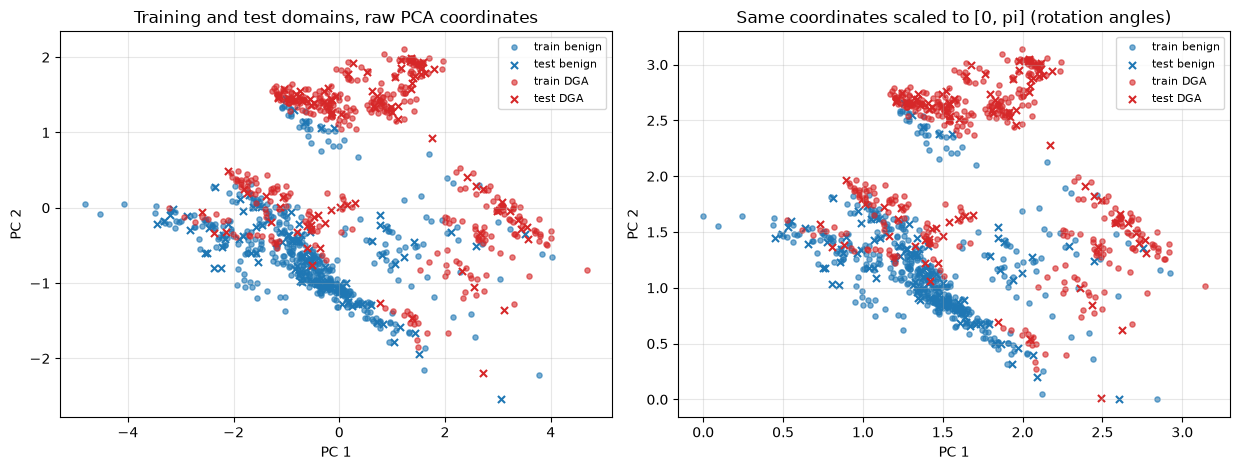

In [7]:
# 2-D scatter of REAL observations coloured by ground-truth label. PCA is fitted on the TRAINING split only.
pca = PCA(n_components=2, random_state=SEED).fit(Xtr)
Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)
print("explained variance ratio of the two PCA axes (train):", pca.explained_variance_ratio_.round(3))
ang = MinMaxScaler((0, np.pi)).fit(Ptr)                       # the angle scaling used by angle encoding (fitted on train only; test clipped)
Atr, Ate = ang.transform(Ptr), np.clip(ang.transform(Pte), 0, np.pi)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, (A, B, ttl) in zip(axes, [(Ptr, Pte, "Training and test domains, raw PCA coordinates"), (Atr, Ate, "Same coordinates scaled to [0, pi] (rotation angles)")]):
    for lab, col, name in [(0, "tab:blue", "benign"), (1, "tab:red", "DGA")]:
        ax.scatter(A[ytr == lab, 0], A[ytr == lab, 1], s=14, alpha=0.6, c=col, label=f"train {name}")
        ax.scatter(B[yte == lab, 0], B[yte == lab, 1], s=26, marker="x", c=col, label=f"test {name}")
    ax.set_title(ttl); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

The paper's Fig. 2 sketches two circuits on two wires. Here they are, drawn from the **real PennyLane QNodes** that the network uses (ideal `default.qubit` device; the noisy versions run the same gates with the
device's noise channels after each gate). The qubit count, circuit depth and number of trainable parameters are printed under the drawings.

In [8]:
# --- the two quantum layers of the paper (Fig. 2): AngleEmbedding followed by BasicEntanglerLayers or RandomLayers (PennyLane templates) ---
CIRCUITS = {"random": "RandomLayers", "basic": "BasicEntanglerLayers"}      # the paper's '*' = random layer, '**' = basic entangler layer

def apply_template(x, w, lay):
    """Queue AngleEmbedding (RX(x_i) on qubit i) + the trainable template on wires 0..N_QUBITS-1 (inside a QNode or an annotated queue)."""
    wires = range(N_QUBITS)
    qml.AngleEmbedding(x, wires=wires, rotation="X")
    if lay == "basic": qml.BasicEntanglerLayers(w, wires=wires)                                      # RX per wire + CNOT (default rotation = RX)
    else:              qml.RandomLayers(w, wires=wires, rotations=[qml.RX], seed=RANDOM_LAYERS_SEED)  # CHOICE: RX only (paper text), random wires / CNOTs

WSHAPE = {"basic": (Q_LAYERS, N_QUBITS), "random": (Q_LAYERS, N_QUBITS)}      # RandomLayers: n_rotations defaults to the number of wires (= 2 here)

def make_qnode(lay):
    """The real PennyLane QNode of the quantum layer (ideal default.qubit simulator): returns <Z_i> of every qubit."""
    dev = qml.device("default.qubit", wires=N_QUBITS)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def qnode(inputs, weights):
        apply_template(inputs, weights, lay)
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
    return qnode


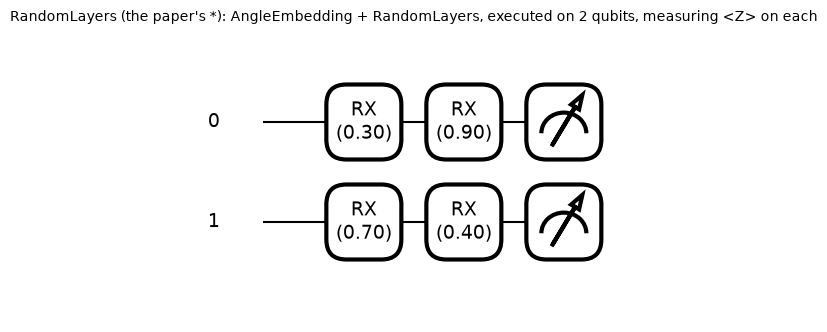

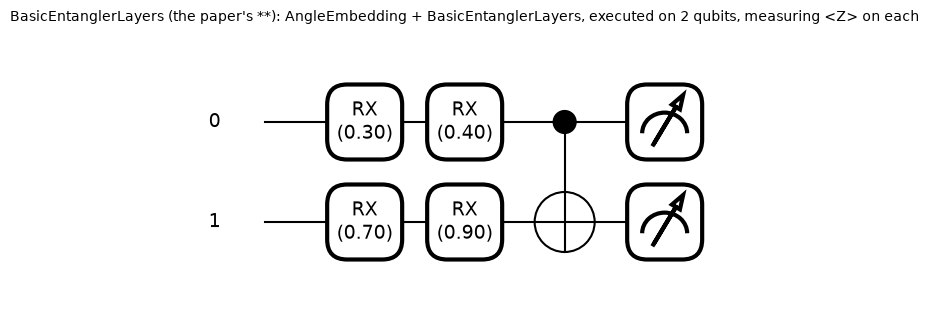

,circuit,qubits,depth,gates,trainable_parameters,input_angles,gate_types
0,RandomLayers,2,2,4,2,2,{'RX': 4}
1,BasicEntanglerLayers,2,3,5,2,2,"{'RX': 4, 'CNOT': 1}"


The whole hybrid network also has Dense(4->2): 10 weights, Dense(2->1): 3 weights, i.e. 13 classical + 2 quantum trainable parameters.
ASSUMPTIONS (the paper shows only the sketch of its Fig. 2): 2 qubits (Fig. 1), 1 layer, RX rotations only; RandomLayers' random choice of gates is fixed by PennyLane's default seed 42,
which here yields no entangling gate at all (two RX on two different wires): the 'random layer' model has no entanglement, the 'basic entangler' model has one CNOT.


In [9]:
# =====  circuit architecture: draw the circuits that are actually executed, with qubit / depth / parameter counts  =====
x_demo = np.array([0.3, 0.7]); w_demo = np.array([[0.4, 0.9]])
rows = []
for lay, nm in CIRCUITS.items():
    qn = make_qnode(lay)
    fig, ax = qml.draw_mpl(qn, decimals=2, level="device")(x_demo, w_demo)
    fig.suptitle(f"{nm} (the paper's {'*' if lay == 'random' else '**'}): AngleEmbedding + {nm}, executed on {N_QUBITS} qubits, measuring <Z> on each", y=1.04, fontsize=10)
    plt.show()
    sp = qml.specs(qn, level="device")(x_demo, w_demo)
    rows.append(dict(circuit=nm, qubits=N_QUBITS, depth=sp.resources.depth, gates=sp.resources.num_gates, trainable_parameters=int(np.prod(WSHAPE[lay])),
                     input_angles=N_QUBITS, gate_types=dict(sp.resources.gate_types)))
display(pd.DataFrame(rows))
print("The whole hybrid network also has Dense(4->2): 10 weights, Dense(2->1): 3 weights, i.e. 13 classical + 2 quantum trainable parameters.")
print("ASSUMPTIONS (the paper shows only the sketch of its Fig. 2): 2 qubits (Fig. 1), 1 layer, RX rotations only; RandomLayers' random choice of gates is fixed by PennyLane's default seed 42,")
print("which here yields no entangling gate at all (two RX on two different wires): the 'random layer' model has no entanglement, the 'basic entangler' model has one CNOT.")


## 4. The quantum layer under noise, and why we need three simulators

* **Reference.** PennyLane's `default.qubit` QNode (above): ideal, exact.
* **Noisy engine.** A small differentiable *density-matrix* simulator (about 60 lines) that runs the recorded gate list and applies, after every gate, depolarising noise, T1/T2 thermal relaxation and readout error, with
  numbers read from the calibration snapshot of the corresponding IBM fake backend. It is **asserted equal to PennyLane** (values *and* gradients, noise-free) and **compared with Qiskit Aer** run with the backend's own noise model.
* **Fast layer.** Each angle of these circuits enters exactly one rotation gate, and a rotation acts on a density matrix linearly in (1, cos, sin). Hence every expectation value is a *multilinear* function of the
  81 products of the feature triples of the 4 angles. We read the 81 coefficients off the engine once (exact linear algebra) and evaluate training steps and attacks with one `einsum`. It is **asserted equal to the engine**
  (values and exact gradients) for both circuits, ideal and with each device's noise. Without this step 100 epochs on a CPU would take hours, as in the paper (8 to 19 hours per run).

Because all expectation values are exact, there is **no shot noise**: gradients are exact, which is the *strongest* setting for a white-box attacker (the paper's `qiskit.aer` runs add shot noise, which can only make gradients less reliable).

In [10]:
# ============ a small differentiable density-matrix simulator with device-calibrated noise (2 qubits -> 4 x 4 matrices) ============
# Why not PennyLane's default.mixed or Aer inside the training loop? They need about a second per training step; this engine does the same maths with
# batched matrix products and exact (autograd) gradients w.r.t. inputs and weights, which the white-box attacks below need.
D = 2 ** N_QUBITS
def _cm(m): return torch.tensor(np.array(m, dtype=complex), dtype=torch.complex128)
PX, PY, PZ = _cm([[0, 1], [1, 0]]), _cm([[0, -1j], [1j, 0]]), _cm([[1, 0], [0, -1]])
I2 = _cm(np.eye(2))
SIGN = torch.tensor([[1 - 2 * ((b >> (N_QUBITS - 1 - q)) & 1) for q in range(N_QUBITS)] for b in range(D)], dtype=torch.float64)   # <Z_q> from probabilities

def left1(rho, U, w):
    """U acting on wire w from the left on a batch of D x D matrices (wire 0 = most significant bit, PennyLane's convention)."""
    B = rho.shape[0]
    r = rho.reshape(B, 2 ** w, 2, -1)
    out = torch.einsum('ij,bajc->baic', U, r) if U.dim() == 2 else torch.einsum('bij,bajc->baic', U, r)
    return out.reshape(B, D, D)
def conj1(rho, U, w):                                   # U rho U^dagger  (U need not be unitary: used for Kraus operators too)
    t = left1(rho, U, w)
    return left1(t.conj().transpose(-1, -2), U, w)
def full_op(K, w):                                      # K on wire w, identity elsewhere (D x D)
    return torch.kron(torch.kron(torch.eye(2 ** w, dtype=torch.complex128), K), torch.eye(2 ** (N_QUBITS - w - 1), dtype=torch.complex128))
def superop(Ks):                                        # Kraus operators (D x D) -> D^2 x D^2 matrix acting on the row-major vec(rho)
    return sum(torch.kron(K, K.conj()) for K in Ks)
def depol_sup(lam, wires):                              # (1-lam) rho + lam * (rho with the given wires completely depolarised)
    full = torch.eye(D * D, dtype=torch.complex128)
    for w in wires: full = superop([full_op(P, w) / 2 for P in (I2, PX, PY, PZ)]) @ full
    return (1 - lam) * torch.eye(D * D, dtype=torch.complex128) + lam * full
def thermal_sup(t, t1, t2, w):
    """Thermal relaxation during a gate of duration t: amplitude damping (T1) followed by the extra pure dephasing implied by T2."""
    t2 = min(t2, 2 * t1)
    g = 1 - np.exp(-t / t1)
    lam = 1 - np.exp(-2 * t * (1 / t2 - 1 / (2 * t1)))
    ad = superop([full_op(_cm([[1, 0], [0, np.sqrt(1 - g)]]), w), full_op(_cm([[0, np.sqrt(g)], [0, 0]]), w)])
    ph = superop([full_op(_cm([[1, 0], [0, np.sqrt(1 - lam)]]), w), full_op(_cm([[0, 0], [0, np.sqrt(lam)]]), w)])
    return ph @ ad
def relax_infidelity(t, t1, t2):                        # average gate infidelity caused by T1/T2 during time t (one qubit)
    t2 = min(t2, 2 * t1)
    return (3 - np.exp(-t / t1) - 2 * np.exp(-t / t2)) / 6

_SUP = {}
def gate_superop(noise, kind, wires, k):
    """Noise channel that follows a gate (depolarising part + thermal relaxation) as ONE cached D^2 x D^2 matrix."""
    key = (id(noise), kind, tuple(wires), k)
    if key not in _SUP:
        if kind == "1q":
            q = wires[0]; t = k * noise["t_sx"]; e = 1 - (1 - noise["sx_err"][q]) ** k
            e_dep = max(e - relax_infidelity(t, noise["t1"][q], noise["t2"][q]), 0.0)     # reported gate error minus the part T1/T2 already explain
            S = thermal_sup(t, noise["t1"][q], noise["t2"][q], q) @ depol_sup(min(2 * e_dep, 1.0), [q])
        else:
            a, b = wires; e, t = noise["cx_err"][a][b], noise["cx_time"][a][b]
            e_dep = max(e - relax_infidelity(t, noise["t1"][a], noise["t2"][a]) - relax_infidelity(t, noise["t1"][b], noise["t2"][b]), 0.0)
            S = (thermal_sup(t, noise["t1"][b], noise["t2"][b], b) @ thermal_sup(t, noise["t1"][a], noise["t2"][a], a) @ depol_sup(min(4 * e_dep / 3, 1.0), [a, b]))
        _SUP[key] = S
    return _SUP[key]
def apply_sup(rho, S): return (rho.reshape(rho.shape[0], D * D) @ S.T).reshape(-1, D, D)

_PERM = {}
def cnot(rho, c, t):
    if (c, t) not in _PERM:
        idx = np.arange(D); _PERM[(c, t)] = torch.tensor(idx ^ (((idx >> (N_QUBITS - 1 - c)) & 1) << (N_QUBITS - 1 - t)), dtype=torch.long)
    p = _PERM[(c, t)]
    return rho[:, p][:, :, p]

def rot_matrix(name, th):
    """RX / RY / RZ matrices for a scalar or a batch of angles (PennyLane's convention, exp(-i theta P / 2))."""
    c, s = torch.cos(th / 2), torch.sin(th / 2); z = torch.zeros_like(c)
    if name == "RX":   re, im = [[c, z], [z, c]], [[z, -s], [-s, z]]
    elif name == "RY": re, im = [[c, -s], [s, c]], [[z, z], [z, z]]
    else:              re, im = [[c, z], [z, c]], [[-s, z], [z, s]]            # RZ = diag(exp(-i theta/2), exp(+i theta/2))
    re = torch.stack([torch.stack(r, -1) for r in re], -2); im = torch.stack([torch.stack(r, -1) for r in im], -2)
    return torch.complex(re, im)

BASIS = {"RX", "RY", "RZ", "CNOT"}
N_PULSES = {"RX": 2, "RY": 2, "RZ": 0}      # CHOICE: sx pulses a rotation costs on IBM hardware (RZ is virtual; neighbouring rotations merge into <= 2 pulses)
def flatten(op):
    if op.name in BASIS: return [op]
    out = []
    for d in op.decomposition(): out += flatten(d)
    return out

STRUCT = {}
def circuit_structure(lay):
    """Record ONCE which gate acts on which wire and which input / weight feeds its angle (found by feeding distinguishable numbers)."""
    if lay not in STRUCT:
        x0 = np.array([0.1234, 0.2345][:N_QUBITS]); w0 = (np.arange(int(np.prod(WSHAPE[lay]))) + 1) * 0.0731 + 0.5
        with qml.queuing.AnnotatedQueue() as q: apply_template(x0, w0.reshape(WSHAPE[lay]), lay)
        ops = []
        for o in q.queue: ops += flatten(o)
        st = []
        for o in ops:
            ws = [int(i) for i in o.wires]
            if o.name == "CNOT": st.append(("CNOT", ws, None)); continue
            v = float(o.parameters[0])
            src = [("x", i) for i in range(len(x0)) if abs(x0[i] - v) < 1e-9] + [("w", j) for j in range(len(w0)) if abs(w0[j] - v) < 1e-9]
            assert len(src) == 1, (o, v); st.append((o.name, ws, src[0]))
        STRUCT[lay] = st
    return STRUCT[lay]

def noisy_expz(x, w, lay, noise=None):
    """<Z_q> of all qubits for a batch x (B x N_QUBITS) by density-matrix simulation of the recorded gate list; noise=None -> ideal.
    x, w are float64 tensors (autograd flows through both); w is the flattened weight vector (P,) or one weight vector per sample (B, P)."""
    B = x.shape[0]
    rho = torch.zeros(B, D, D, dtype=torch.complex128); rho[:, 0, 0] = 1
    pending = [0] * N_QUBITS
    def flush(rho, q):
        if noise is not None and pending[q] > 0: rho = apply_sup(rho, gate_superop(noise, "1q", [q], pending[q]))
        pending[q] = 0
        return rho
    for name, ws, src in circuit_structure(lay):
        if name == "CNOT":
            for q in ws: rho = flush(rho, q)
            rho = cnot(rho, *ws)
            if noise is not None: rho = apply_sup(rho, gate_superop(noise, "2q", ws, None))
        else:
            th = x[:, src[1]] if src[0] == "x" else w[..., src[1]]
            rho = conj1(rho, rot_matrix(name, th), ws[0])
            pending[ws[0]] = min(2, pending[ws[0]] + N_PULSES[name])
    for q in range(N_QUBITS): rho = flush(rho, q)
    ez = torch.einsum('bd,dq->bq', torch.diagonal(rho, dim1=1, dim2=2).real, SIGN)
    if noise is not None: ez = ez * (1 - 2 * torch.tensor(noise["ro"], dtype=torch.float64))   # symmetric readout error flips <Z> by (1-2r)
    return ez

class EngineLayer(nn.Module):
    """The quantum layer of the hybrid network: trainable weights + the density-matrix engine (ideal if noise is None)."""
    def __init__(self, lay, noise=None):
        super().__init__()
        self.lay, self.noise = lay, noise
        w = torch.empty(*WSHAPE[lay]); nn.init.uniform_(w, -Q_INIT, Q_INIT)
        self.weights = nn.Parameter(w)
    def forward(self, x):
        return noisy_expz(x.double(), self.weights.double().reshape(-1), self.lay, self.noise).float()


In [11]:
# --- noise parameters read from the fake IBM backends (calibration snapshots shipped with qiskit-ibm-runtime) ---
ALL_DEVICES = {"ibmq_belem": "FakeBelemV2", "ibmq_lima": "FakeLimaV2", "ibmq_quito": "FakeQuitoV2", "ibmq_santiago": "FakeSantiagoV2"}   # the paper's four noise models

def best_chain(backend, k=N_QUBITS):
    """The path of k coupled physical qubits with the smallest summed CNOT + readout error (what a noise-aware layout would pick)."""
    t = backend.target
    edges = {tuple(q): p.error for q, p in t["cx"].items()}
    ro = {q[0]: p.error for q, p in t["measure"].items()}
    adj = {}
    for (a, b) in edges: adj.setdefault(a, set()).add(b)
    best, best_cost = None, 1e9
    def dfs(path):
        nonlocal best, best_cost
        if len(path) == k:
            cost = sum(min(edges.get((path[i], path[i + 1]), 1), edges.get((path[i + 1], path[i]), 1)) for i in range(k - 1)) + sum(ro[q] for q in path)
            if cost < best_cost: best, best_cost = list(path), cost
            return
        for nb in adj.get(path[-1], ()):
            if nb not in path: dfs(path + [nb])
    for s in adj: dfs([s])
    return best

def device_noise(backend, k=N_QUBITS):
    """Gate errors, durations, T1/T2 and readout errors of the chosen k-qubit chain, in the dictionary format of noisy_expz."""
    t = backend.target
    chain = best_chain(backend, k)
    one = "sx" if "sx" in t.operation_names else "u2"
    edges = {tuple(q): p for q, p in t["cx"].items()}
    get = lambda a, b: edges[(a, b)] if (a, b) in edges else edges[(b, a)]
    e_cx = float(np.mean([get(chain[i], chain[i + 1]).error for i in range(k - 1)]))
    t_cx = float(np.mean([get(chain[i], chain[i + 1]).duration for i in range(k - 1)]))
    cx_err, cx_time = np.zeros((k, k)), np.zeros((k, k))
    for a in range(k):
        for b in range(k):
            if a != b:
                hops = 1 + 3 * (abs(a - b) - 1)          # a CNOT over chain distance d costs 1 + 3(d-1) CNOTs after SWAP routing (d = 1 here, so 1)
                cx_err[a, b] = 1 - (1 - e_cx) ** hops; cx_time[a, b] = hops * t_cx
    return dict(chain=chain, sx_err=[t[one][(q,)].error for q in chain], t_sx=float(np.mean([t[one][(q,)].duration for q in chain])),
                t1=[backend.qubit_properties(q).t1 for q in chain], t2=[backend.qubit_properties(q).t2 for q in chain],
                ro=[t["measure"][(q,)].error for q in chain], cx_err=cx_err.tolist(), cx_time=cx_time.tolist(), e_cx=e_cx)

BACKENDS, NOISE = {}, {}
for name in ALL_DEVICES:
    BACKENDS[name] = getattr(fake_provider, ALL_DEVICES[name])()
    NOISE[name] = device_noise(BACKENDS[name])
display(pd.DataFrame({name: dict(backend=ALL_DEVICES[name], chain=str(NOISE[name]["chain"]), sx_error=np.mean(NOISE[name]["sx_err"]), cx_error=NOISE[name]["e_cx"],
                                 readout_error=np.mean(NOISE[name]["ro"]), T1_us=np.mean(NOISE[name]["t1"]) * 1e6, T2_us=np.mean(NOISE[name]["t2"]) * 1e6)
                      for name in ALL_DEVICES}).T.round(5))


,backend,chain,sx_error,cx_error,readout_error,T1_us,T2_us
ibmq_belem,FakeBelemV2,"[1, 2]",0.000354,0.010693,0.028,73.688113,51.194773
ibmq_lima,FakeLimaV2,"[1, 2]",0.000256,0.005962,0.0183,93.418459,105.151222
ibmq_quito,FakeQuitoV2,"[0, 1]",0.001288,0.013267,0.03315,54.204612,57.948058
ibmq_santiago,FakeSantiagoV2,"[3, 4]",0.000181,0.0052,0.0126,137.866727,107.596745


In [12]:
# --- the engine must agree with the real PennyLane QNode (ideal, values AND gradients) and be close to Qiskit Aer with the backend's own noise model ---
g = np.random.default_rng(SEED)
rows = []
for lay, nm in CIRCUITS.items():
    qn = make_qnode(lay)
    X = torch.tensor(g.uniform(0, 3, (6, N_QUBITS)), dtype=torch.float64, requires_grad=True)
    W = torch.tensor(g.uniform(-3, 3, WSHAPE[lay]), dtype=torch.float64, requires_grad=True)
    ref = torch.stack(qn(X, W), dim=-1)
    eng = noisy_expz(X, W.reshape(-1), lay, None)
    gx_r, gw_r = torch.autograd.grad(ref.sum(), [X, W]); gx_e, gw_e = torch.autograd.grad(eng.sum(), [X, W])
    d_val, d_gx, d_gw = float((ref - eng).abs().max()), float((gx_r - gx_e).abs().max()), float((gw_r - gw_e).abs().max())
    assert d_val < 1e-10 and d_gx < 1e-10 and d_gw < 1e-10, (lay, d_val, d_gx, d_gw)
    rows.append(dict(circuit=nm, max_diff_expectation=d_val, max_diff_grad_wrt_input=d_gx, max_diff_grad_wrt_weights=d_gw))
display(pd.DataFrame(rows))
print("ASSERTED: the engine equals PennyLane's default.qubit QNode (values and gradients) to better than 1e-10 for both circuits.")

def to_qiskit(lay, x, w):
    qc = QuantumCircuit(N_QUBITS, N_QUBITS)
    for name, ws, src in circuit_structure(lay):
        if name == "CNOT": qc.cx(*ws); continue
        th = float(x[src[1]] if src[0] == "x" else w[src[1]])
        {"RX": qc.rx, "RY": qc.ry, "RZ": qc.rz}[name](th, ws[0])
    qc.measure(range(N_QUBITS), range(N_QUBITS))
    return qc
def aer_expz(lay, x, w, backend, chain, shots):
    sim = AerSimulator.from_backend(backend, seed_simulator=SEED)
    tqc = transpile(to_qiskit(lay, x, w), sim, initial_layout=chain, optimization_level=1, seed_transpiler=SEED)
    counts = sim.run(tqc, shots=shots).result().get_counts()
    z = np.zeros(N_QUBITS)
    for key, c in counts.items():
        for q in range(N_QUBITS): z[q] += c * (1 - 2 * int(key[::-1][q]))
    return z / shots
rows = []
for name in DEVICES_USED:
    for lay, nm in CIRCUITS.items():
        W = g.uniform(-3, 3, WSHAPE[lay]); X = g.uniform(0, 3, (4, N_QUBITS))
        eng = noisy_expz(torch.tensor(X), torch.tensor(W).reshape(-1), lay, NOISE[name]).numpy()
        ideal = noisy_expz(torch.tensor(X), torch.tensor(W).reshape(-1), lay, None).numpy()
        aer = np.array([aer_expz(lay, x, W.reshape(-1), BACKENDS[name], NOISE[name]["chain"], AER_SHOTS) for x in X])
        rows.append(dict(device=name, circuit=nm, ideal_vs_aer=np.abs(ideal - aer).mean(), engine_vs_aer=np.abs(eng - aer).mean(), max_engine_vs_aer=np.abs(eng - aer).max(),
                         ideal_vs_engine=np.abs(ideal - eng).mean(), shot_noise=1 / np.sqrt(AER_SHOTS)))
AERCHK = pd.DataFrame(rows); display(AERCHK.round(4))
assert AERCHK.max_engine_vs_aer.max() < 0.06, "noisy engine drifted away from Qiskit Aer"
print("The engine follows Aer's noisy expectation values to within shot noise plus a few hundredths. Device noise on a 2-qubit, 1-layer circuit is small:")
print("the gap ideal-vs-noisy is only about", float(AERCHK.ideal_vs_engine.mean().round(3)), "in <Z>, which is why the four noise models will turn out nearly indistinguishable (as in the paper).")


,circuit,max_diff_expectation,max_diff_grad_wrt_input,max_diff_grad_wrt_weights
0,RandomLayers,5.551115e-16,4.440892e-16,8.881784e-16
1,BasicEntanglerLayers,2.775558e-16,2.220446e-16,8.881784e-16


ASSERTED: the engine equals PennyLane's default.qubit QNode (values and gradients) to better than 1e-10 for both circuits.


,device,circuit,ideal_vs_aer,engine_vs_aer,max_engine_vs_aer,ideal_vs_engine,shot_noise
0,ibmq_belem,RandomLayers,0.0315,0.0021,0.0042,0.0319,0.0071
1,ibmq_belem,BasicEntanglerLayers,0.0422,0.0049,0.0075,0.0471,0.0071
2,ibmq_lima,RandomLayers,0.0265,0.0026,0.0053,0.0279,0.0071
3,ibmq_lima,BasicEntanglerLayers,0.0286,0.0031,0.0060,0.0309,0.0071
4,ibmq_quito,RandomLayers,0.0448,0.0054,0.0087,0.0487,0.0071
5,ibmq_quito,BasicEntanglerLayers,0.0623,0.0032,0.0062,0.0654,0.0071
6,ibmq_santiago,RandomLayers,0.0154,0.0024,0.0099,0.0153,0.0071
7,ibmq_santiago,BasicEntanglerLayers,0.0142,0.0028,0.0081,0.0129,0.0071


The engine follows Aer's noisy expectation values to within shot noise plus a few hundredths. Device noise on a 2-qubit, 1-layer circuit is small:
the gap ideal-vs-noisy is only about 0.035 in <Z>, which is why the four noise models will turn out nearly indistinguishable (as in the paper).


In [13]:
# ============  an exact, fast version of the engine for training and attacking (asserted equal to the engine below)  ============
# Every angle of these circuits enters exactly ONE rotation gate, and a rotation acts on a density matrix linearly in (1, cos theta, sin theta).
# Hence, for a fixed circuit and fixed device noise, every <Z_q> is a MULTILINEAR function of the feature triples (1, cos, sin) of the 4 angles
# (2 inputs + 2 weights): <Z_q> = sum_{abcd} C[a,b,c,d,q] f(x0)_a f(x1)_b f(w0)_c f(w1)_d.  We read the 3^4 = 81 coefficients off the slow engine once
# (exact linear algebra, no fitting) and then evaluate a training step with one einsum instead of ~100 small density-matrix operations.
import itertools
GRID = np.array([0.0, np.pi / 2, np.pi])
MF = np.array([[1.0, np.cos(t), np.sin(t)] for t in GRID]); MINV = np.linalg.inv(MF)
_COEF = {}
def coefficients(lay, noise):
    key = (lay, None if noise is None else id(noise))
    if key not in _COEF:
        st = circuit_structure(lay); srcs = [s[2] for s in st if s[2] is not None]
        assert len(srcs) == len(set(srcs)) == 4, "each angle must enter exactly one gate for the multilinear shortcut"
        pts = list(itertools.product(range(3), repeat=4))                       # grid over (x0, x1, w0, w1)
        X = torch.tensor([[GRID[p[0]], GRID[p[1]]] for p in pts], dtype=torch.float64)
        W = torch.tensor([[GRID[p[2]], GRID[p[3]]] for p in pts], dtype=torch.float64)   # one weight vector per grid point (batched weights)
        vals = noisy_expz(X, W, lay, noise).numpy().reshape(3, 3, 3, 3, N_QUBITS)
        C = vals
        for k in range(4): C = np.moveaxis(np.tensordot(MINV, C, axes=([1], [k])), 0, k)
        _COEF[key] = torch.tensor(C, dtype=torch.float64)
    return _COEF[key]
def feats(th): return torch.stack([torch.ones_like(th), torch.cos(th), torch.sin(th)], dim=-1)

class FastLayer(nn.Module):
    """Drop-in replacement of EngineLayer: same weights, same outputs (asserted), one einsum per forward pass, exact autograd gradients."""
    def __init__(self, lay, noise=None):
        super().__init__()
        self.lay, self.noise = lay, noise
        w = torch.empty(*WSHAPE[lay]); nn.init.uniform_(w, -Q_INIT, Q_INIT)
        self.weights = nn.Parameter(w)
        self.C = coefficients(lay, noise)
    def forward(self, x):
        x = x.double(); w = self.weights.double().reshape(-1)
        fw = feats(w)                                                         # (2, 3)
        return torch.einsum('abcdq,za,zb,c,d->zq', self.C, feats(x[:, 0]), feats(x[:, 1]), fw[0], fw[1]).float()

rows = []
g = np.random.default_rng(SEED)
for lay, nm in CIRCUITS.items():
    for dev in [None] + list(ALL_DEVICES):
        nz = None if dev is None else NOISE[dev]
        fl = FastLayer(lay, nz); fl.weights.data = torch.tensor(g.uniform(-3, 3, WSHAPE[lay]), dtype=torch.float32)
        X = torch.tensor(g.uniform(0, 3, (50, N_QUBITS)), dtype=torch.float32, requires_grad=True)
        Wd = fl.weights.detach().double().reshape(-1).clone().requires_grad_(True)
        eng = noisy_expz(X.double(), Wd, lay, nz)
        fast = fl(X)
        gx_e, gw_e = torch.autograd.grad(eng.sum(), [X, Wd], retain_graph=True)
        gx_f, = torch.autograd.grad(fast.sum(), [X])
        gw_f, = torch.autograd.grad(fl(X).sum(), [fl.weights])
        d = float((eng - fast.double()).abs().max()); dg = float(max((gx_e - gx_f).abs().max(), (gw_e - gw_f.reshape(-1).double()).abs().max()))
        assert d < 1e-6 and dg < 1e-4, (lay, dev, d, dg)          # the layer works in float32 at its interface (values ~1e-8, summed gradients ~1e-6 are float32 rounding)
        rows.append(dict(circuit=nm, noise=dev or "ideal", max_diff_value=d, max_diff_gradient=dg))
display(pd.DataFrame(rows).round(9))
print("ASSERTED: the fast multilinear layer reproduces the density-matrix engine (values and exact gradients) for both circuits, ideal and with each device's noise.")
print("Together with the previous check (engine == PennyLane QNode, 1e-10), the layer used for training IS the PennyLane circuit (ideal) or its noisy density-matrix version.")


,circuit,noise,max_diff_value,max_diff_gradient
0,RandomLayers,ideal,3.000000e-08,6.530000e-07
1,RandomLayers,ibmq_belem,2.900000e-08,9.080000e-07
2,RandomLayers,ibmq_lima,3.000000e-08,1.501000e-06
3,RandomLayers,ibmq_quito,3.000000e-08,9.010000e-07
4,RandomLayers,ibmq_santiago,3.000000e-08,8.980000e-07
5,BasicEntanglerLayers,ideal,2.900000e-08,1.250000e-07
6,BasicEntanglerLayers,ibmq_belem,2.800000e-08,6.320000e-07
7,BasicEntanglerLayers,ibmq_lima,2.900000e-08,4.490000e-07
8,BasicEntanglerLayers,ibmq_quito,2.900000e-08,6.620000e-07
9,BasicEntanglerLayers,ibmq_santiago,2.900000e-08,9.010000e-07


ASSERTED: the fast multilinear layer reproduces the density-matrix engine (values and exact gradients) for both circuits, ideal and with each device's noise.
Together with the previous check (engine == PennyLane QNode, 1e-10), the layer used for training IS the PennyLane circuit (ideal) or its noisy density-matrix version.


## 5. The hybrid network, the classical counterpart and training

`HybridNet` is the paper's Fig. 1. With `q=None` it becomes the **classical counterpart** `Dense(4->2) -> Dropout -> Dense(2->1)` (13 parameters; the hybrid has 15). `WideNet` is a stronger classical reference
(225 parameters) that is not in the paper. All models start from the same seed, so hybrid and classical counterpart share their Dense initialisation.
Training is Adam on binary cross-entropy with shuffled mini-batches. First we choose the learning rate on a **validation split of the training data** (no test data involved).

In [14]:
class HybridNet(nn.Module):
    """Paper Fig. 1:  Dense(4->2, relu) -> Dropout -> quantum layer (2 qubits -> 2 numbers) -> Dense(2->1, sigmoid).
    q=None -> the classical counterpart  Dense(4->2, relu) -> Dropout -> Dense(2->1, sigmoid)  (same Dense initialisation)."""
    def __init__(self, q=None, hidden=HIDDEN):
        super().__init__()
        self.d1 = nn.Linear(4, hidden); self.drop = nn.Dropout(DROPOUT); self.out = nn.Linear(N_QUBITS if q is not None else hidden, 1)
        for m in (self.d1, self.out): nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)     # Keras defaults: Glorot-uniform weights, zero biases
        self.q = q
    def forward(self, x):
        h = self.drop(torch.relu(self.d1(x)))
        if self.q is not None: h = self.q(h)
        return self.out(h).squeeze(-1)                     # logit; the sigmoid is inside the loss / the prediction

class WideNet(nn.Module):
    """A stronger classical reference that has nothing to do with the paper: Dense(4->16) -> Dense(16->8) -> Dropout -> Dense(8->1)."""
    def __init__(self):
        super().__init__()
        self.d1, self.d2, self.drop, self.out = nn.Linear(4, 16), nn.Linear(16, 8), nn.Dropout(DROPOUT), nn.Linear(8, 1)
        for m in (self.d1, self.d2, self.out): nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x): return self.out(self.drop(torch.relu(self.d2(torch.relu(self.d1(x)))))).squeeze(-1)

def n_params(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build(kind, noise_name=None, seed=SEED):
    """kind: 'classical' | 'wide' | 'basic' | 'random' (hybrid; noise_name = device or None for ideal). Same seed -> same Dense initialisation."""
    seed_everything(seed)
    if kind == "classical": return HybridNet(None)
    if kind == "wide": return WideNet()
    q = FastLayer(kind, None if noise_name is None else NOISE[noise_name])
    return HybridNet(q)

def train_model(model, X, y, epochs, seed, lr):
    """Adam + binary cross-entropy on shuffled mini-batches (seeded generator). Returns the mean training loss of every epoch."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, yt = torch.from_numpy(X), torch.from_numpy(y)
    g = torch.Generator().manual_seed(seed)
    hist = []
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(Xt), generator=g); tot = 0.0
        for i in range(0, len(Xt), BATCH):
            idx = order[i:i + BATCH]
            opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(model(Xt[idx]), yt[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        hist.append(tot / len(Xt))
    model.eval()
    return hist

def predict_proba(model, X):
    model.eval()
    with torch.no_grad(): return torch.sigmoid(model(torch.as_tensor(np.asarray(X, dtype=np.float32)))).numpy()
def predict(model, X): return (predict_proba(model, X) > 0.5).astype(int)
def full_metrics(model, X, y):
    p = predict_proba(model, X); yh = (p > 0.5).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return dict(TP=int(tp), FP=int(fp), TN=int(tn), FN=int(fn), acc=accuracy_score(y, yh), precision=precision_score(y, yh, zero_division=0),
                recall=recall_score(y, yh, zero_division=0), auc=roc_auc_score(y, p))

# timing + parameter counts of the three network types
for kind in ["classical", "random", "basic", "wide"]:
    m = build(kind, "ibmq_belem" if kind in ("random", "basic") else None)
    t0 = time.time(); train_model(m, Xtr[:256], ytr[:256], 1, SEED, 0.01)
    print(f"{kind:9s} trainable parameters {n_params(m):4d} | one epoch on 256 samples: {time.time()-t0:5.2f} s")


classical trainable parameters   13 | one epoch on 256 samples: 22.13 s
random    trainable parameters   15 | one epoch on 256 samples:  0.14 s


basic     trainable parameters   15 | one epoch on 256 samples:  0.15 s
wide      trainable parameters  225 | one epoch on 256 samples:  0.09 s


In [15]:
# Learning rate: the paper does not state it. CHOICE: pick it on a VALIDATION split of the training data (never the test set), noise-free engine, seed SEED.
Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=0.2, random_state=SEED)
rows = []
for lr in LR_GRID:
    for kind in ["classical", "random", "basic"]:
        m = build(kind, None); train_model(m, Xa, ya, EPOCHS, SEED, lr)
        rows.append(dict(lr=lr, model=kind, val_acc=accuracy_score(yv, predict(m, Xv))))
LRT = pd.DataFrame(rows).pivot(index="lr", columns="model", values="val_acc"); LRT["mean"] = LRT.mean(axis=1)
display(LRT.round(3))
LR = float(LRT["mean"].idxmax())
print("selected learning rate (best mean validation accuracy over the three models):", LR)


model,basic,classical,random,mean
lr,,,,
0.003,0.882,0.894,0.888,0.888
0.010,0.882,0.888,0.894,0.888
0.030,0.882,0.882,0.888,0.884


selected learning rate (best mean validation accuracy over the three models): 0.003


## 6. The attacks

The paper uses ART's FGSM, PGD and BIM. We re-implement them for any differentiable PyTorch model (so the *same code* attacks the hybrid and the classical networks):

* **FGSM** (Eq. 1 of the paper): `x + eps * sign(grad_x loss)`, clipped to [-5, 5].
* **BIM** (Kurakin): repeat small steps of size `eps_step = 0.1`, project onto the eps-ball; as in ART, a sample that is already misclassified stops moving.
* **PGD** (Madry): same steps for all iterations; ART's default has no random start.
* For the audit we add **adaptive attacks**: PGD with random starts and restarts on the cross-entropy and on the *margin* loss (`-(2y-1) * logit`, which never saturates), a **gradient-free black-box search** over random corners of the eps-box, and a
  **transfer attack** from another model. The strong attacks start from random points / random corners of the eps-ball, because a ReLU network has regions where the gradient is exactly zero and an attack that starts there never moves.

Gradients are exact (autograd through the quantum layer), the model is in evaluation mode, and "accuracy under attack" is measured on **all** test samples (also those misclassified without attack), like in the paper's tables.

In [16]:
# =====  adversarial attacks on the feature vectors (L-infinity ball of radius eps, inside the valid box [-CLIP, CLIP])  =====
# (the valid box is [-CLIP, CLIP], see the configuration cell)
# All white-box attacks use the EXACT gradient of the network (autograd through the density-matrix engine); the model is in eval mode (no dropout).
def _t(a): return torch.as_tensor(np.asarray(a), dtype=torch.float32)

def grad_of(model, X, y, loss="ce"):
    """Gradient of the attack loss w.r.t. the input features. 'ce' = cross-entropy (what FGSM/PGD in ART ascend);
    'margin' = -(2y-1) * logit: never saturates, so it still has a gradient when the sigmoid is flat (the standard check against gradient masking)."""
    X = X.clone().requires_grad_(True)
    z = model(X)
    L = F.binary_cross_entropy_with_logits(z, y, reduction="sum") if loss == "ce" else (-(2 * y - 1) * z).sum()
    return torch.autograd.grad(L, X)[0]

def fgsm(model, X, y, eps, loss="ce"):
    """Eq. (1) of the paper: x + eps * sign(grad_x J(theta, x, y)), clipped to [0, 1]."""
    X, y = _t(X), _t(y); model.eval()
    return torch.clamp(X + eps * grad_of(model, X, y, loss).sign(), -CLIP, CLIP).detach()

def iterative(model, X, y, eps, step, iters, loss="ce", rand_start=False, early_stop=False, gen=None):
    """BIM (early_stop=True: samples that are already misclassified stop moving, like ART's BasicIterativeMethod) or PGD (all iterations).
    rand_start=True / "uniform" starts from a random point of the eps-ball (Madry et al.), "corner" from a random corner of the ball; ART's default PGD has no random start."""
    X0, y = _t(X), _t(y); model.eval(); x = X0.clone()
    if rand_start == "corner": x = torch.clamp(X0 + eps * (2 * (torch.rand(X0.shape, generator=gen) > 0.5).float() - 1), -CLIP, CLIP)
    elif rand_start: x = torch.clamp(X0 + eps * (2 * torch.rand(X0.shape, generator=gen) - 1), -CLIP, CLIP)
    for _ in range(iters):
        g = grad_of(model, x, y, loss)
        upd = x + step * g.sign()
        if early_stop:
            with torch.no_grad(): still_right = ((torch.sigmoid(model(x)) > 0.5).float() == y)
            upd = torch.where(still_right[:, None], upd, x)
        x = torch.clamp(torch.min(torch.max(upd, X0 - eps), X0 + eps), -CLIP, CLIP)
    return x.detach()

def margin_of(model, X, y):
    with torch.no_grad(): return ((2 * _t(y) - 1) * model(_t(X))).numpy()          # > 0: correctly classified; smaller = closer to being fooled

def strong_attack(model, X, y, eps, loss="margin", iters=None, restarts=None, seed=SEED):
    """Adaptive white-box attack: random starts (alternating uniform / corner of the eps-ball), step eps/4, exact gradient; keeps, per sample, the restart with the smallest margin.
    Random starts matter: a ReLU network has regions with an exactly zero gradient, where sign(0) = 0 and a gradient attack that starts there never moves."""
    iters, restarts = iters or STRONG_ITERS, restarts or RESTARTS
    gen = torch.Generator().manual_seed(seed); best, best_m = None, None
    for r in range(restarts):
        xa = iterative(model, X, y, eps, eps / 4, iters, loss=loss, rand_start="corner" if r % 2 == 0 else "uniform", gen=gen)
        m = margin_of(model, xa, y)
        if best is None: best, best_m = xa.clone(), m
        else:
            better = torch.as_tensor(m < best_m); best = torch.where(better[:, None], xa, best); best_m = np.minimum(best_m, m)
    return best

def acc_on(model, X, y): return float((predict(model, X) == np.asarray(y)).mean())

def attack(model, X, y, name, eps):
    """The paper's three attacks with ART defaults (eps_step 0.1, max_iter = ITERS) plus the adaptive ones used in the audit."""
    if name == "none":   return _t(X)
    if name == "fgsm":   return fgsm(model, X, y, eps)
    if name == "bim":    return iterative(model, X, y, eps, min(ART_STEP, eps), ITERS, early_stop=True)
    if name == "pgd":    return iterative(model, X, y, eps, min(ART_STEP, eps), ITERS)
    if name == "pgd_ce_strong":     return strong_attack(model, X, y, eps, "ce")
    if name == "pgd_margin_strong": return strong_attack(model, X, y, eps, "margin")
    raise ValueError(name)

def robust_acc(model, X, y, name, eps): return acc_on(model, attack(model, X, y, name, eps).numpy(), y)

def vertex_search_ok(pred_fn, X, y, eps, n_queries, seed=SEED):
    """Black-box, gradient-free attack that works for ANY classifier (also RF / SVC): try n_queries random corners of the eps-box around each sample,
    the sample counts as broken if ANY query is misclassified. No gradient is used, so gradient masking cannot hide anything from it."""
    r = np.random.default_rng(seed); X = np.asarray(X); y = np.asarray(y)
    ok = pred_fn(X) == y
    for _ in range(n_queries):
        ok &= pred_fn(np.clip(X + eps * r.choice([-1.0, 1.0], size=X.shape), -CLIP, CLIP).astype(np.float32)) == y
    return ok                                  # boolean vector: True = the sample survived every query

def vertex_search_acc(pred_fn, X, y, eps, n_queries, seed=SEED): return float(vertex_search_ok(pred_fn, X, y, eps, n_queries, seed).mean())


## 7. Training everything

For every seed and every configuration we (1) train the **base** model on the clean training set, (2) craft FGSM(0.3) examples of the training set against it, (3) train a **new hardened** model of the same kind on clean + adversarial examples
(paper Fig. 3). Configurations: two quantum circuits x the noise models, plus the two classical networks. Random forest and RBF-SVM are trained on the clean training set only.

In [17]:
# =====  the whole experiment grid: base model and hardened model for {2 circuits} x {noise models}, plus classical references  =====
# Adversarial training (paper Fig. 3): craft FGSM(eps = 0.3) examples from the TRAINING set against the trained base model, add them (with their true
# labels) to the training set (it doubles) and train a NEW model of the same kind from scratch on clean + adversarial examples.
STORE = {}       # (seed, kind, device, role) -> trained model
HIST = {}        # same key -> per-epoch training loss
DATA = {}        # seed -> (Xtr, Xte, ytr, yte, Xmix, ymix)  Xmix = clean test + FGSM(0.3) examples crafted against that seed's base model of the same kind
TIMES = {}
RECORDS = []

def kinds_for_run():
    out = [("classical", None), ("wide", None)]
    for lay in ["random", "basic"]:
        for dev in DEVICES_USED: out.append((lay, dev))
    return out

t_all = time.time()
for si in range(N_SEEDS):
    seed = SEED + si
    Xtr_, Xte_, ytr_, yte_ = prepare(seed); DATA[seed] = (Xtr_, Xte_, ytr_, yte_)
    for kind, dev in kinds_for_run():
        t0 = time.time()
        base = build(kind, dev, seed); HIST[(seed, kind, dev, "base")] = train_model(base, Xtr_, ytr_, EPOCHS, seed, LR)
        t_base = time.time() - t0
        Xadv = fgsm(base, Xtr_, ytr_, EPS_DEFAULT).numpy()                                     # adversarial examples for the hardening (paper Fig. 3)
        hard = build(kind, dev, seed)
        HIST[(seed, kind, dev, "hard")] = train_model(hard, np.concatenate([Xtr_, Xadv]), np.concatenate([ytr_, ytr_]), EPOCHS, seed, LR)
        STORE[(seed, kind, dev, "base")], STORE[(seed, kind, dev, "hard")] = base, hard
        TIMES[(seed, kind, dev)] = (t_base, time.time() - t0 - t_base)
        print(f"seed {seed} {kind:9s} {str(dev):14s} clean test acc base {acc_on(base, Xte_, yte_):.3f} | hardened {acc_on(hard, Xte_, yte_):.3f} "
              f"| train time base {t_base:5.1f} s, hardened {TIMES[(seed, kind, dev)][1]:5.1f} s | elapsed {(time.time()-t_all)/60:5.1f} min", flush=True)
    # sklearn references (no gradient): trained on the clean training set only
    STORE[(seed, "rf", None, "base")] = RandomForestClassifier(n_estimators=100, random_state=seed).fit(Xtr_, ytr_)
    STORE[(seed, "svc", None, "base")] = SVC(kernel="rbf", C=1.0, probability=False, random_state=seed).fit(Xtr_, ytr_)
print(f"all models trained in {(time.time()-t_all)/60:.1f} min")


seed 42 classical None           clean test acc base 0.899 | hardened 0.814 | train time base  18.9 s, hardened  41.4 s | elapsed   1.0 min


seed 42 wide      None           clean test acc base 0.920 | hardened 0.824 | train time base  26.8 s, hardened  56.7 s | elapsed   2.4 min


seed 42 random    ibmq_belem     clean test acc base 0.899 | hardened 0.824 | train time base  67.8 s, hardened 127.0 s | elapsed   5.6 min


seed 42 random    ibmq_lima      clean test acc base 0.899 | hardened 0.824 | train time base  64.2 s, hardened 127.4 s | elapsed   8.8 min


seed 42 random    ibmq_quito     clean test acc base 0.899 | hardened 0.824 | train time base  69.3 s, hardened 140.8 s | elapsed  12.3 min


...

seed 44 basic     ibmq_belem     clean test acc base 0.884 | hardened 0.819 | train time base  59.2 s, hardened 131.8 s | elapsed  76.7 min


seed 44 basic     ibmq_lima      clean test acc base 0.884 | hardened 0.819 | train time base  60.8 s, hardened  82.5 s | elapsed  79.1 min


seed 44 basic     ibmq_quito     clean test acc base 0.879 | hardened 0.819 | train time base  38.6 s, hardened  69.1 s | elapsed  80.9 min


seed 44 basic     ibmq_santiago  clean test acc base 0.884 | hardened 0.819 | train time base  48.1 s, hardened  66.3 s | elapsed  82.8 min


all models trained in 82.8 min


## 8. Evaluation protocols

Two ways of measuring the hardened model, because they answer different questions:

* **Paper protocol (`mixed`).** The test set of the hardened model is *doubled*: the 199 clean samples plus their 199 FGSM(0.3) twins crafted against the **base** model (398 samples, like the paper's Table 3). The attacks are then run on this doubled set.
  This is what produces the paper's Tables 3, 4 and 6 -- but it contains examples that were built to fool a *different* model and that the hardened model has seen the like of during training, so its accuracy is partly inflated.
* **Like-for-like (`clean`).** Base and hardened model are attacked on the same 199 clean test samples. This is what a defender would need to know.

All attack numbers below are accuracies after the attack, on the stated test set; a "drop" is the clean accuracy of the same model on the same test set minus the accuracy after the attack, in points.

In [18]:
# =====  the paper's own tables, transcribed by hand from the PDF (the tables are vector drawings: typed in once and cross-checked against the paper's text below)  =====
DEV4 = ["ibmq_belem", "ibmq_lima", "ibmq_quito", "ibmq_santiago"]
def _by(kind, vals): return {(kind, d): v for d, v in zip(DEV4, vals)}
# Table 1: base models, accuracy / precision / recall / AUC on the 199 test samples ('*' random layer, '**' basic entangler)
PT1_ACC = {**_by("random", [.844, .844, .844, .844]), **_by("basic", [.854, .859, .859, .859])}
PT1_PREC = {**_by("random", [.883] * 4), **_by("basic", [.962, .963, .963, .963])}
PT1_REC = {**_by("random", [.806] * 4), **_by("basic", [.748, .757, .757, .757])}
PT1_AUC = {**_by("random", [.949, .953, .951, .948]), **_by("basic", [.894, .907, .899, .903])}
# Table 2: base models under attack at eps = 0.3  (acc without attack, FGSM, PGD, BIM)
PT2 = {**_by("random", [(.844, .834, .744, .829), (.844, .834, .754, .829), (.844, .834, .744, .829), (.844, .844, .754, .834)]),
       **_by("basic", [(.854, .693, .578, .688), (.859, .688, .573, .688), (.859, .683, .568, .678), (.859, .683, .573, .693)])}
# Table 3: hardened models, accuracy on the doubled (clean + adversarial) test set of 398 samples
PT3_ACC = {**_by("random", [.884, .882, .879, .884]), **_by("basic", [.842, .852, .847, .849])}
# Table 4: hardened models under attack at eps = 0.3  (acc without attack, FGSM, PGD, BIM)
PT4 = {**_by("random", [(.884, .819, .606, .824), (.882, .819, .601, .824), (.879, .812, .611, .822), (.884, .812, .611, .814)]),
       **_by("basic", [(.842, .731, .656, .726), (.852, .726, .658, .729), (.847, .734, .663, .734), (.849, .729, .661, .739)])}
# Tables 5 and 6: FGSM accuracy for the 18 attack strengths (EPS_GRID), base and hardened
PT5 = {**_by("random", [[.842, .837, .832, .834, .832, .829, .832, .829, .827, .834, .812, .754, .719, .673, .621, .593, .565, .548],
                        [.842, .837, .837, .832, .834, .832, .834, .832, .827, .824, .799, .749, .721, .676, .621, .588, .568, .550],
                        [.839, .837, .832, .832, .834, .824, .827, .822, .834, .827, .799, .756, .716, .671, .621, .583, .568, .553],
                        [.839, .832, .834, .834, .824, .829, .832, .827, .824, .829, .807, .754, .711, .668, .621, .585, .565, .553]]),
       **_by("basic", [[.769, .759, .761, .749, .749, .746, .739, .746, .731, .731, .666, .626, .601, .585, .578, .568, .573, .575],
                       [.769, .769, .766, .746, .751, .744, .741, .746, .746, .731, .681, .628, .598, .588, .575, .568, .570, .568],
                       [.764, .771, .769, .754, .751, .751, .744, .741, .736, .736, .666, .633, .606, .593, .580, .570, .565, .570],
                       [.769, .771, .766, .754, .751, .746, .739, .739, .729, .731, .691, .631, .603, .580, .580, .570, .565, .568]])}
PT6 = {**_by("random", [[.887, .884, .882, .879, .882, .879, .879, .884, .867, .862, .844, .822, .771, .726, .676, .631, .595, .573],
                        [.882, .884, .882, .882, .879, .877, .877, .869, .864, .872, .844, .817, .766, .729, .676, .626, .606, .573],
                        [.887, .884, .887, .877, .877, .879, .867, .877, .869, .857, .842, .819, .769, .736, .681, .631, .606, .575],
                        [.884, .884, .879, .882, .877, .877, .879, .867, .872, .859, .834, .819, .771, .726, .676, .628, .603, .573]]),
       **_by("basic", [[.842, .844, .844, .842, .837, .844, .844, .834, .832, .829, .784, .734, .683, .628, .606, .585, .588, .583],
                       [.842, .847, .837, .844, .842, .847, .852, .844, .839, .832, .786, .729, .671, .646, .598, .578, .575, .580],
                       [.849, .847, .847, .844, .849, .844, .844, .847, .827, .832, .784, .736, .681, .643, .606, .585, .580, .588],
                       [.847, .847, .842, .842, .842, .842, .832, .837, .842, .832, .789, .726, .673, .643, .593, .575, .573, .580]])}

# cross-check the transcription against the numbers the paper states in its text
drops = lambda T: np.array([[a[0] - a[j] for j in (1, 2, 3)] for a in T.values()])
base_drop, hard_drop = drops(PT2), drops(PT4)
kinds_ = np.array([k for (k, d) in PT2])
print(f"paper text: average drop of the base model 12.4 %      -> transcribed Table 2: {100*base_drop.mean():.1f} %")
print(f"paper text: PGD average drop 19 %, worst drop 29.1 %    -> transcribed: {100*base_drop[:, 1].mean():.1f} % and {100*base_drop.max():.1f} %")
print(f"paper text: basic entangler 20.9 %, random layer 3.9 %  -> transcribed: {100*base_drop[kinds_=='basic'].mean():.1f} % and {100*base_drop[kinds_=='random'].mean():.1f} %")
print(f"paper text: average drop of the hardened model 13.8 %   -> transcribed Table 4: {100*hard_drop.mean():.1f} %  (the text rounds differently by 0.1)")
v5 = np.array(list(PT5.values())); v6 = np.array(list(PT6.values()))
tt = stats.ttest_ind(v5.ravel(), v6.ravel(), equal_var=False)
print(f"paper text: mean gain 5.9 %, t = -4.7829, df = 283.41  -> transcribed Tables 5/6: gain {100*(v6.mean()-v5.mean()):.1f} %, Welch t = {tt.statistic:.4f}, df = {tt.df:.2f}")
print(f"paper text: hardened higher than base in 100 % of the experiments -> transcribed: {100*(v6 > v5).mean():.0f} % of the 144 pairs (eps x configuration)")
print("paper text: noise models average 74.8 / 74.8 / 74.9 / 74.9 % -> transcribed: " + " / ".join(f"{100*np.mean([np.mean(PT5[(k, d)] + PT6[(k, d)]) for k in ('random', 'basic')]):.1f}" for d in DEV4) + " %")


paper text: average drop of the base model 12.4 %      -> transcribed Table 2: 12.4 %
paper text: PGD average drop 19 %, worst drop 29.1 %    -> transcribed: 19.0 % and 29.1 %
paper text: basic entangler 20.9 %, random layer 3.9 %  -> transcribed: 20.9 % and 3.9 %
paper text: average drop of the hardened model 13.8 %   -> transcribed Table 4: 13.7 %  (the text rounds differently by 0.1)
paper text: mean gain 5.9 %, t = -4.7829, df = 283.41  -> transcribed Tables 5/6: gain 5.9 %, Welch t = -4.7829, df = 283.41
paper text: hardened higher than base in 100 % of the experiments -> transcribed: 100 % of the 144 pairs (eps x configuration)
paper text: noise models average 74.8 / 74.8 / 74.9 / 74.9 % -> transcribed: 74.8 / 74.8 / 74.9 / 74.7 %


In [19]:
# =====  evaluate every trained model: clean metrics, attacks at eps = 0.3, FGSM sweep over the 18 attack strengths  =====
# Protocols (see the markdown): 'clean'   = the 199 clean test samples (base models; and hardened models, like-for-like)
#                               'mixed'   = paper-style test set of the hardened model: the clean test samples + their FGSM(0.3) twins crafted against the BASE model (398 samples)
EV, CL = [], []
def name_of(kind, dev): return f"{dev}{'*' if kind == 'random' else '**'}" if kind in ("random", "basic") else {"classical": "classical Dense(2)", "wide": "classical wide MLP"}[kind]

t_ev = time.time()
for seed in DATA:
    Xtr_, Xte_, ytr_, yte_ = DATA[seed]
    for kind, dev in kinds_for_run():
        base, hard = STORE[(seed, kind, dev, "base")], STORE[(seed, kind, dev, "hard")]
        Xmix = np.concatenate([Xte_, fgsm(base, Xte_, yte_, EPS_DEFAULT).numpy()]); ymix = np.concatenate([yte_, yte_])
        for role, model, protocol, X, y in [("base", base, "clean", Xte_, yte_), ("hard", hard, "mixed", Xmix, ymix), ("hard", hard, "clean", Xte_, yte_)]:
            CL.append(dict(seed=seed, kind=kind, device=dev, role=role, protocol=protocol, n_test=len(y), **full_metrics(model, X, y)))
            for atk in ("fgsm", "pgd", "bim"):
                EV.append(dict(seed=seed, kind=kind, device=dev, role=role, protocol=protocol, attack=atk, eps=EPS_DEFAULT, acc=robust_acc(model, X, y, atk, EPS_DEFAULT)))
            for eps in EPS_GRID:
                EV.append(dict(seed=seed, kind=kind, device=dev, role=role, protocol=protocol, attack="fgsm_sweep", eps=eps, acc=robust_acc(model, X, y, "fgsm", eps)))
    print(f"seed {seed} evaluated | elapsed {(time.time()-t_ev)/60:.1f} min", flush=True)
EV, CL = pd.DataFrame(EV), pd.DataFrame(CL)
print(len(EV), "attack evaluations,", len(CL), "clean evaluations")


seed 42 evaluated | elapsed 1.5 min


seed 43 evaluated | elapsed 3.1 min


seed 44 evaluated | elapsed 4.7 min


1890 attack evaluations, 90 clean evaluations


## 9. Table 1: the base models

**What we see.** All eight base models reach 88-92 % on the 199 test samples (mean 89.7 %), 4-6 points *above* the paper's 84-86 %, and the four noise models give identical confusion matrices (same seed). The classical counterpart without the quantum layer
(13 parameters) reaches 89.9 %, the wide classical MLP 92 %, a random forest 91 % and an RBF-SVM 91.5 %: **the quantum layer brings no accuracy advantage on these four features**. With 199 test samples the binomial standard error of a 90 % accuracy is about 2.1 points,
so none of these differences is significant. Unlike the paper, the random-layer circuit is slightly *better* than the basic entangler here (90.1 vs 89.2 %).

,model,TP,FP,TN,FN,acc,precision,recall,auc,paper acc,train time (s)
0,ibmq_belem*,80,7,99,13,0.899,0.920,0.860,0.963,0.844,67.765
1,ibmq_lima*,80,7,99,13,0.899,0.920,0.860,0.963,0.844,64.183
2,ibmq_quito*,80,7,99,13,0.899,0.920,0.860,0.963,0.844,69.250
3,ibmq_santiago*,80,7,99,13,0.899,0.920,0.860,0.963,0.844,72.382
4,ibmq_belem**,76,5,101,17,0.889,0.938,0.817,0.962,0.854,89.216
5,ibmq_lima**,76,5,101,17,0.889,0.938,0.817,0.962,0.859,70.143
6,ibmq_quito**,76,5,101,17,0.889,0.938,0.817,0.962,0.859,68.460
7,ibmq_santiago**,76,5,101,17,0.889,0.938,0.817,0.962,0.859,75.035


classical references on the same data (no quantum layer): {'classical Dense(2)': 0.899, 'classical wide MLP': 0.92}
random forest / RBF-SVM on the same 4 features: {'rf': 0.91, 'svc': 0.915}

over all seeds and noise models: base accuracy max 92.0 / mean 89.7 / min 87.9 %  (paper: 85.9 / 85.1 / 84.4 %)
by circuit (mean over seeds and noise models): {'basic': 89.2, 'random': 90.1}  paper: random 84.4 %, basic entangler 85.8 %
one test sample = 0.50 accuracy points; the paper's own four noise models differ by at most 0.5 points from each other (they used one seed).


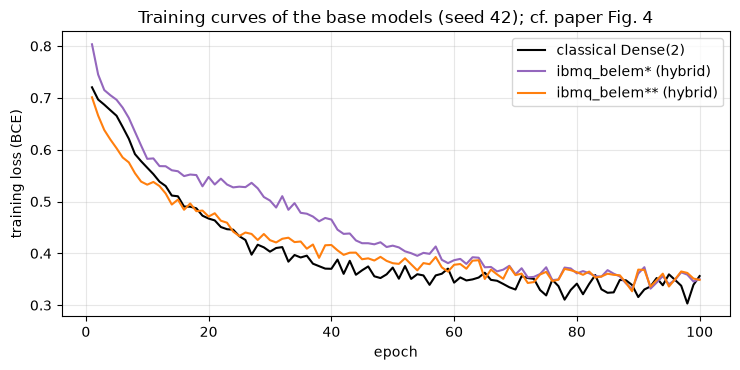

In [20]:
# =====  Table 1: the base models  =====
S0 = SEED
c = CL[(CL.seed == S0) & (CL.role == "base") & (CL.protocol == "clean") & CL.kind.isin(["random", "basic"])].copy()
c["model"] = [name_of(k, d) for k, d in zip(c.kind, c.device)]
c["paper acc"] = [PT1_ACC[(k, d)] for k, d in zip(c.kind, c.device)]
c["train time (s)"] = [TIMES[(S0, k, d)][0] for k, d in zip(c.kind, c.device)]
display(c[["model", "TP", "FP", "TN", "FN", "acc", "precision", "recall", "auc", "paper acc", "train time (s)"]].round(3).reset_index(drop=True))
other = CL[(CL.seed == S0) & (CL.role == "base") & CL.kind.isin(["classical", "wide"])]
print("classical references on the same data (no quantum layer):", {name_of(r.kind, r.device): round(r.acc, 3) for r in other.itertuples()})
rfsvc = {}
for nm in ("rf", "svc"):
    m = STORE[(S0, nm, None, "base")]; rfsvc[nm] = round(accuracy_score(DATA[S0][3], m.predict(DATA[S0][1])), 3)
print("random forest / RBF-SVM on the same 4 features:", rfsvc)
bb = CL[(CL.role == "base") & (CL.protocol == "clean") & CL.kind.isin(["random", "basic"])]
print(f"\nover all seeds and noise models: base accuracy max {100*bb.acc.max():.1f} / mean {100*bb.acc.mean():.1f} / min {100*bb.acc.min():.1f} %  (paper: 85.9 / 85.1 / 84.4 %)")
print("by circuit (mean over seeds and noise models):", {k: round(100 * v, 1) for k, v in bb.groupby("kind").acc.mean().items()}, " paper: random 84.4 %, basic entangler 85.8 %")
print("one test sample = 0.50 accuracy points; the paper's own four noise models differ by at most 0.5 points from each other (they used one seed).")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for (kind, dev), col in zip([("classical", None), ("random", DEVICES_USED[0]), ("basic", DEVICES_USED[0])], ["k", "tab:purple", "tab:orange"]):
    h = HIST[(S0, kind, dev, "base")]; ax.plot(range(1, len(h) + 1), h, color=col, label=name_of(kind, dev) + (" (hybrid)" if dev else ""))
ax.set_xlabel("epoch"); ax.set_ylabel("training loss (BCE)"); ax.set_title(f"Training curves of the base models (seed {S0}); cf. paper Fig. 4"); ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


## 10. Table 2: vulnerability of the base models (eps = 0.3)

**What we see.** With exact gradients the base models are *much* more vulnerable than in the paper: at eps = 0.3 (0.3 standard deviations of each feature) the accuracy falls from about 90 % to 45-48 %, a drop of 36 points on average (paper: 12.4), and FGSM, BIM and PGD end up
at the same number because for this tiny network a single signed step already reaches the worst corner of the eps-box. The paper's most striking numbers -- the random-layer circuit losing only 3.9 points, PGD being twice as damaging as FGSM -- do **not** appear. Note also that the paper's Table 2 and
Table 5 disagree with each other at eps = 0.3 (FGSM on the random-layer model: 0.834 in Table 2, 0.754 in Table 5), which suggests that its attack numbers are not a stable quantity.

In [21]:
# =====  Table 2: vulnerability of the base models at eps = 0.3 (FGSM, PGD, BIM, ART defaults)  =====
def attack_table(role, protocol, PAPER, seed=None):
    e = EV[(EV.role == role) & (EV.protocol == protocol) & (EV.eps == EPS_DEFAULT) & EV.attack.isin(["fgsm", "pgd", "bim"]) & EV.kind.isin(["random", "basic"])]
    if seed is not None: e = e[e.seed == seed]
    clean = CL[(CL.role == role) & (CL.protocol == protocol) & CL.kind.isin(["random", "basic"])][["seed", "kind", "device", "acc"]].rename(columns={"acc": "clean"})
    w = e.pivot_table(index=["seed", "kind", "device"], columns="attack", values="acc").reset_index().merge(clean, on=["seed", "kind", "device"])
    for a in ("fgsm", "pgd", "bim"): w["drop_" + a] = w["clean"] - w[a]
    w["model"] = [name_of(k, d) for k, d in zip(w.kind, w.device)]
    w["paper (acc / FGSM / PGD / BIM)"] = [" / ".join(f"{x:.3f}" for x in PAPER[(k, d)]) for k, d in zip(w.kind, w.device)]
    return w
T2 = attack_table("base", "clean", PT2)
display(T2[T2.seed == S0][["model", "clean", "fgsm", "pgd", "bim", "paper (acc / FGSM / PGD / BIM)"]].round(3).reset_index(drop=True))
def drop_summary(T, tag):
    allv = T[["drop_fgsm", "drop_pgd", "drop_bim"]]
    out = {"average drop (3 attacks)": 100 * allv.values.mean(), "PGD average drop": 100 * T.drop_pgd.mean(), "worst single drop": 100 * allv.values.max(),
           "basic-entangler average drop": 100 * T[T.kind == "basic"][["drop_fgsm", "drop_pgd", "drop_bim"]].values.mean(),
           "random-layer average drop": 100 * T[T.kind == "random"][["drop_fgsm", "drop_pgd", "drop_bim"]].values.mean()}
    out = {k: float(v) for k, v in out.items()}
    print(tag, {k: round(v, 1) for k, v in out.items()}); return out
D2 = drop_summary(T2, "base model, mean over seeds and noise models (points):")
print("paper (points):                                           {'average drop (3 attacks)': 12.4, 'PGD average drop': 19.0, 'worst single drop': 29.1, 'basic-entangler average drop': 20.9, 'random-layer average drop': 3.9}")
print("per attack, mean drop (points):", {a: round(float(100 * T2["drop_" + a].mean()), 1) for a in ("fgsm", "pgd", "bim")}, "  paper:", {a: round(float(100 * v), 1) for a, v in zip(("fgsm", "pgd", "bim"), drops(PT2).mean(axis=0))})


,model,clean,fgsm,pgd,bim,paper (acc / FGSM / PGD / BIM)
0,ibmq_belem**,0.889,0.447,0.447,0.447,0.854 / 0.693 / 0.578 / 0.688
1,ibmq_lima**,0.889,0.452,0.452,0.452,0.859 / 0.688 / 0.573 / 0.688
2,ibmq_quito**,0.889,0.447,0.447,0.447,0.859 / 0.683 / 0.568 / 0.678
3,ibmq_santiago**,0.889,0.452,0.452,0.452,0.859 / 0.683 / 0.573 / 0.693
4,ibmq_belem*,0.899,0.482,0.482,0.482,0.844 / 0.834 / 0.744 / 0.829
5,ibmq_lima*,0.899,0.477,0.477,0.477,0.844 / 0.834 / 0.754 / 0.829
6,ibmq_quito*,0.899,0.482,0.482,0.482,0.844 / 0.834 / 0.744 / 0.829
7,ibmq_santiago*,0.899,0.477,0.477,0.477,0.844 / 0.844 / 0.754 / 0.834


base model, mean over seeds and noise models (points): {'average drop (3 attacks)': 36.2, 'PGD average drop': 36.3, 'worst single drop': 44.2, 'basic-entangler average drop': 35.1, 'random-layer average drop': 37.2}
paper (points):                                           {'average drop (3 attacks)': 12.4, 'PGD average drop': 19.0, 'worst single drop': 29.1, 'basic-entangler average drop': 20.9, 'random-layer average drop': 3.9}
per attack, mean drop (points): {'fgsm': 36.0, 'pgd': 36.3, 'bim': 36.3}   paper: {'fgsm': 8.9, 'pgd': 19.0, 'bim': 9.2}


## 11. Tables 3 and 4: the hardened models

**What we see.** Adversarial training works in the like-for-like setting: at eps = 0.3 the attacked accuracy of the hardened models is 74-75 % against 53-54 % for the base models (about +21 points, all three attacks), but it costs clean accuracy (89.7 % -> 81-82 %), because training on eps = 0.3 examples
is a strong regulariser for a 15-parameter model. On the paper's doubled test set the hardened model scores 81 %, not the paper's 86 %, and its drop at eps = 0.3 (11.6 points) is *smaller* than the base model's (36 points), whereas the paper found it slightly larger (13.8 vs 12.4).

In [22]:
# =====  Tables 3 and 4: the hardened models  =====
c = CL[(CL.seed == S0) & (CL.role == "hard") & CL.kind.isin(["random", "basic"])]
cm_ = c[c.protocol == "mixed"].set_index(["kind", "device"]); cc_ = c[c.protocol == "clean"].set_index(["kind", "device"])
T3 = cm_[["n_test", "TP", "FP", "TN", "FN", "acc", "precision", "recall", "auc"]].copy()
T3["acc on clean test only"] = cc_["acc"]; T3["paper acc"] = [PT3_ACC[i] for i in T3.index]
T3["train time (s)"] = [TIMES[(S0, k, d)][1] for k, d in T3.index]
T3.index = [name_of(k, d) for k, d in T3.index]
print("Table 3 (hardened models). 'acc' is measured on the paper-style doubled test set (clean + FGSM(0.3) twins crafted against the base model, 398 samples);")
print("'acc on clean test only' is the same model on the 199 clean test samples.")
display(T3.round(3))
T4m = attack_table("hard", "mixed", PT4)
print("Table 4 (hardened models under attack at eps = 0.3), paper-style doubled test set:")
display(T4m[T4m.seed == S0][["model", "clean", "fgsm", "pgd", "bim", "paper (acc / FGSM / PGD / BIM)"]].round(3).reset_index(drop=True))
D4m = drop_summary(T4m, "hardened, paper protocol (mixed test set), mean over seeds and noise models (points):")
T4c = attack_table("hard", "clean", PT4)
D4c = drop_summary(T4c, "hardened, like-for-like (clean test set), mean over seeds and noise models (points):")
print("paper (points): hardened average drop 13.8 vs base 12.4  ->  'adversarial training did not reduce the drop at eps = 0.3'")
print("base model on the clean test set for comparison:", {k: round(v, 1) for k, v in D2.items() if k in ('average drop (3 attacks)', 'PGD average drop')})
print("attacked ACCURACY at eps = 0.3 (mean over seeds / noise models / circuits), clean test set:  base vs hardened:")
for a in ("fgsm", "pgd", "bim"):
    print(f"   {a.upper():5s} base {100*T2[a].mean():5.1f} %   hardened {100*T4c[a].mean():5.1f} %   gain {100*(T4c[a].mean()-T2[a].mean()):+5.1f} points")


Table 3 (hardened models). 'acc' is measured on the paper-style doubled test set (clean + FGSM(0.3) twins crafted against the base model, 398 samples);
'acc on clean test only' is the same model on the 199 clean test samples.


,n_test,TP,FP,TN,FN,acc,precision,recall,auc,acc on clean test only,paper acc,train time (s)
ibmq_belem*,398,136,23,189,50,0.817,0.855,0.731,0.835,0.824,0.884,126.977
ibmq_lima*,398,136,23,189,50,0.817,0.855,0.731,0.835,0.824,0.882,127.423
ibmq_quito*,398,136,23,189,50,0.817,0.855,0.731,0.834,0.824,0.879,140.821
ibmq_santiago*,398,136,23,189,50,0.817,0.855,0.731,0.835,0.824,0.884,145.896
ibmq_belem**,398,126,16,196,60,0.809,0.887,0.677,0.806,0.809,0.842,197.182
ibmq_lima**,398,126,16,196,60,0.809,0.887,0.677,0.805,0.809,0.852,126.659
ibmq_quito**,398,126,16,196,60,0.809,0.887,0.677,0.805,0.809,0.847,149.250
ibmq_santiago**,398,126,17,195,60,0.807,0.881,0.677,0.804,0.809,0.849,133.364


Table 4 (hardened models under attack at eps = 0.3), paper-style doubled test set:

,model,clean,fgsm,pgd,bim,paper (acc / FGSM / PGD / BIM)
0,ibmq_belem**,0.809,0.729,0.729,0.729,0.842 / 0.731 / 0.656 / 0.726
1,ibmq_lima**,0.809,0.724,0.724,0.724,0.852 / 0.726 / 0.658 / 0.729
2,ibmq_quito**,0.809,0.731,0.731,0.731,0.847 / 0.734 / 0.663 / 0.734
3,ibmq_santiago**,0.807,0.729,0.729,0.729,0.849 / 0.729 / 0.661 / 0.739
4,ibmq_belem*,0.817,0.666,0.658,0.658,0.884 / 0.819 / 0.606 / 0.824
5,ibmq_lima*,0.817,0.666,0.658,0.658,0.882 / 0.819 / 0.601 / 0.824
6,ibmq_quito*,0.817,0.666,0.661,0.661,0.879 / 0.812 / 0.611 / 0.822
7,ibmq_santiago*,0.817,0.666,0.656,0.656,0.884 / 0.812 / 0.611 / 0.814


hardened, paper protocol (mixed test set), mean over seeds and noise models (points): {'average drop (3 attacks)': 11.6, 'PGD average drop': 12.0, 'worst single drop': 16.3, 'basic-entangler average drop': 11.1, 'random-layer average drop': 12.1}


hardened, like-for-like (clean test set), mean over seeds and noise models (points): {'average drop (3 attacks)': 7.4, 'PGD average drop': 7.5, 'worst single drop': 16.1, 'basic-entangler average drop': 8.2, 'random-layer average drop': 6.5}
paper (points): hardened average drop 13.8 vs base 12.4  ->  'adversarial training did not reduce the drop at eps = 0.3'
base model on the clean test set for comparison: {'average drop (3 attacks)': 36.2, 'PGD average drop': 36.3}
attacked ACCURACY at eps = 0.3 (mean over seeds / noise models / circuits), clean test set:  base vs hardened:
   FGSM  base  53.7 %   hardened  75.2 %   gain +21.6 points
   PGD   base  53.4 %   hardened  74.5 %   gain +21.1 points
   BIM   base  53.4 %   hardened  74.4 %   gain +20.9 points


## 12. Tables 5 and 6, Figs. 5-7: the repeated-experiment robustness measurement (18 attack strengths)

The paper's measurement idea: instead of one attack strength, run FGSM for eps = 0.01 ... 0.9 and compare the *averages* and a t-test. It is a sensible way to avoid "measurement traps" (a single eps can make two models look equal), but note two things:
the 18 accuracies of one model are *not independent* observations (the accuracy at eps and at eps + 0.01 are almost the same number), and the 8 configurations differ only in the noise model, which hardly matters, so the paper's df of 283 greatly overstates the real sample size. We therefore also show the plain
numbers (gain, share of wins), which do not depend on the independence assumption.

**What we see.** The averages of the paper are matched numerically (gain 4.8 points on the paper's protocol, 7.4 like-for-like, paper 5.9) but **the shape behind the average is different**: the paper's hardened model is 6-7 points better at *every* attack strength, ours is *worse* than the base model for
eps up to about 0.1 (its clean accuracy is lower) and much better from eps = 0.2 on (up to +27 points around eps = 0.4). Hence the hardened model beats the base model in only 48 % of the (configuration, eps) pairs, not 100 %, and an average over a grid in which 10 of the 18 values lie below eps = 0.1 is dominated by that
region. The Welch t-test (mean t = -2.1 on the paper protocol, p = 0.12; like-for-like p < 0.02 in every seed) is anyway questionable because the 18 accuracies of one model are strongly correlated.

Table 5 analogue: base models, FGSM accuracy for each attack strength (seed 42 )


eps,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,Average
ibmq_belem**,0.879,0.874,0.874,0.874,0.859,0.849,0.849,0.844,0.809,0.799,0.658,0.447,0.312,0.296,0.291,0.296,0.296,0.296,0.634
ibmq_lima**,0.879,0.874,0.874,0.874,0.864,0.849,0.849,0.839,0.809,0.799,0.653,0.452,0.312,0.296,0.291,0.296,0.296,0.296,0.634
ibmq_quito**,0.879,0.874,0.874,0.874,0.859,0.849,0.849,0.844,0.809,0.799,0.658,0.447,0.312,0.296,0.291,0.296,0.296,0.296,0.634
ibmq_santiago**,0.879,0.874,0.874,0.874,0.864,0.849,0.849,0.839,0.809,0.799,0.648,0.452,0.312,0.296,0.291,0.291,0.296,0.296,0.633
ibmq_belem*,0.894,0.884,0.884,0.874,0.864,0.859,0.859,0.849,0.839,0.834,0.638,0.482,0.407,0.382,0.342,0.302,0.281,0.276,0.653
ibmq_lima*,0.894,0.889,0.884,0.869,0.864,0.859,0.859,0.849,0.839,0.834,0.638,0.477,0.407,0.382,0.342,0.302,0.281,0.276,0.653
ibmq_quito*,0.894,0.884,0.884,0.874,0.864,0.859,0.859,0.849,0.839,0.829,0.638,0.482,0.407,0.377,0.337,0.296,0.276,0.271,0.651
ibmq_santiago*,0.894,0.889,0.884,0.869,0.864,0.859,0.859,0.849,0.839,0.829,0.638,0.477,0.407,0.382,0.342,0.302,0.281,0.276,0.652


Table 6 analogue: hardened models on the paper-style doubled test set (seed 42 )


eps,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,Average
ibmq_belem**,0.807,0.807,0.807,0.807,0.807,0.804,0.804,0.804,0.804,0.799,0.779,0.729,0.648,0.560,0.495,0.415,0.359,0.352,0.688
ibmq_lima**,0.807,0.807,0.807,0.807,0.804,0.804,0.804,0.804,0.804,0.796,0.779,0.724,0.646,0.560,0.495,0.415,0.362,0.349,0.687
ibmq_quito**,0.807,0.807,0.807,0.807,0.807,0.804,0.804,0.804,0.799,0.799,0.779,0.731,0.643,0.555,0.503,0.410,0.359,0.352,0.687
ibmq_santiago**,0.807,0.807,0.807,0.807,0.804,0.804,0.804,0.804,0.802,0.796,0.779,0.729,0.646,0.563,0.500,0.420,0.359,0.349,0.688
ibmq_belem*,0.812,0.809,0.807,0.804,0.804,0.804,0.802,0.796,0.791,0.784,0.726,0.666,0.601,0.472,0.392,0.329,0.322,0.317,0.658
ibmq_lima*,0.812,0.809,0.804,0.804,0.804,0.802,0.802,0.796,0.789,0.784,0.721,0.666,0.595,0.475,0.382,0.324,0.317,0.312,0.655
ibmq_quito*,0.814,0.809,0.807,0.804,0.804,0.804,0.804,0.799,0.791,0.789,0.749,0.666,0.608,0.513,0.415,0.337,0.324,0.312,0.664
ibmq_santiago*,0.812,0.809,0.804,0.804,0.804,0.802,0.796,0.794,0.789,0.784,0.719,0.666,0.595,0.475,0.382,0.327,0.317,0.312,0.655


Hardened models on the CLEAN test set only (like-for-like with Table 5)


eps,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,Average
ibmq_belem**,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.774,0.719,0.633,0.583,0.487,0.402,0.397,0.716
ibmq_lima**,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.774,0.719,0.638,0.588,0.492,0.402,0.397,0.717
ibmq_quito**,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.779,0.714,0.633,0.593,0.482,0.402,0.397,0.717
ibmq_santiago**,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.809,0.779,0.719,0.643,0.593,0.503,0.402,0.402,0.719
ibmq_belem*,0.819,0.819,0.814,0.809,0.809,0.809,0.809,0.804,0.799,0.799,0.789,0.769,0.729,0.568,0.472,0.382,0.367,0.357,0.696
ibmq_lima*,0.819,0.819,0.809,0.809,0.809,0.809,0.809,0.804,0.799,0.799,0.789,0.769,0.729,0.568,0.472,0.382,0.367,0.357,0.695
ibmq_quito*,0.824,0.819,0.814,0.809,0.809,0.809,0.809,0.809,0.799,0.799,0.789,0.769,0.729,0.623,0.492,0.392,0.367,0.347,0.700
ibmq_santiago*,0.819,0.819,0.809,0.809,0.809,0.809,0.804,0.804,0.799,0.799,0.789,0.769,0.729,0.568,0.472,0.387,0.367,0.357,0.695


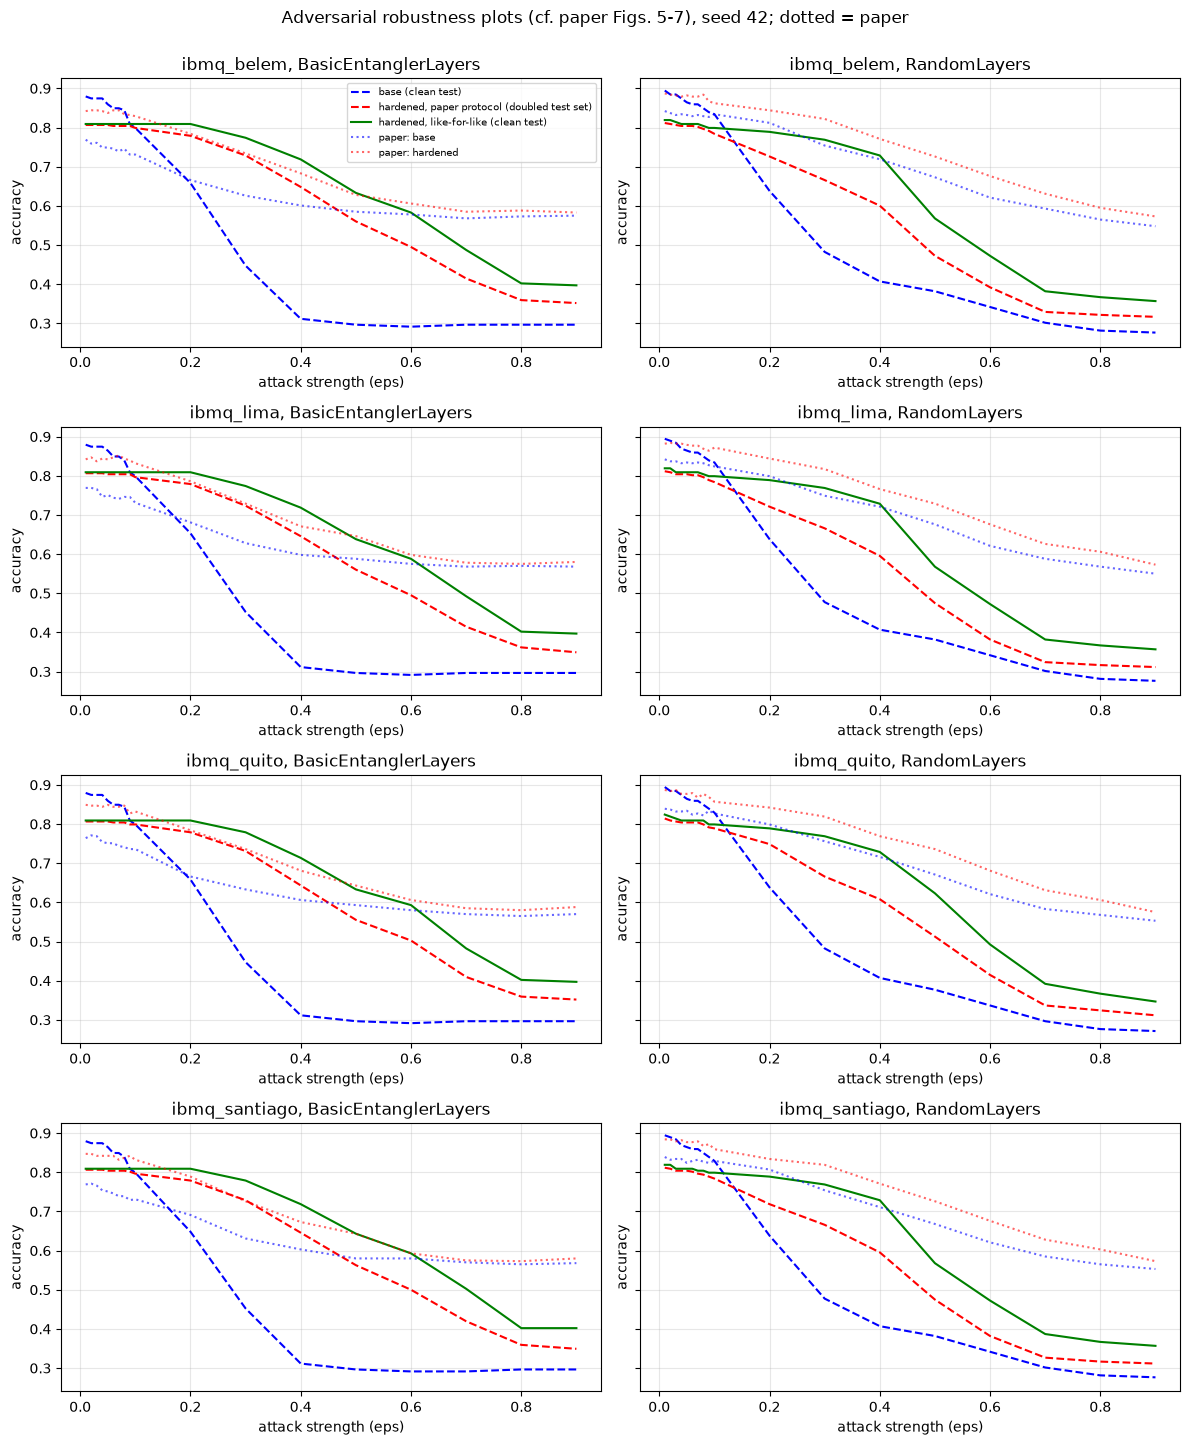

,seed,mean_base,mean_hardened_paper_protocol,gain_paper_protocol,share_pairs_hardened_higher,welch_t,df,p_two_sided,mean_hardened_like_for_like,gain_like_for_like,share_pairs_higher_like_for_like,t_like_for_like,p_like_for_like
0,42,64.297,67.281,2.984,44.444,-1.149,257.659,0.252,70.701,6.404,47.222,-2.563,0.011
1,43,66.897,70.837,3.940,44.444,-1.575,220.153,0.117,73.482,6.585,44.444,-2.671,0.008
2,44,65.808,73.157,7.349,55.556,-3.698,196.060,0.000,75.140,9.331,58.333,-4.770,0.000


paper: gain 5.9 points, hardened higher in 100 % of the pairs, Welch t = -4.7829 (df 283.41) -> 'statistically significant'


eps,0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.1,0.1,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
gain paper protocol (points),-8.0,-7.4,-7.1,-6.2,-5.2,-4.5,-4.4,-3.6,-2.3,-1.9,6.6,16.8,21.5,19.2,18.9,17.4,17.3,18.3
gain like-for-like (points),-7.1,-6.5,-6.2,-5.4,-4.3,-3.7,-3.5,-2.6,-1.4,-0.8,9.4,21.6,27.2,24.5,25.2,23.1,21.8,22.7
paper gain (points),6.1,6.4,6.3,7.0,7.0,7.4,7.3,7.2,7.0,6.6,7.3,8.4,6.4,5.5,3.9,2.7,2.3,1.7


In [23]:
# =====  Tables 5 and 6, Figs. 5-7: repeated experiments over 18 attack strengths  =====
def sweep(role, protocol):
    e = EV[(EV.role == role) & (EV.protocol == protocol) & (EV.attack == "fgsm_sweep") & EV.kind.isin(["random", "basic"])]
    return e.pivot_table(index=["seed", "kind", "device"], columns="eps", values="acc")[EPS_GRID]
SW5, SW6A, SW6B = sweep("base", "clean"), sweep("hard", "mixed"), sweep("hard", "clean")
def avg_table(sw, seed=S0):
    s = sw.loc[seed].copy(); s["Average"] = s.mean(axis=1); s.index = [name_of(k, d) for k, d in s.index]; return s
print("Table 5 analogue: base models, FGSM accuracy for each attack strength (seed", S0, ")")
display(avg_table(SW5).round(3))
print("Table 6 analogue: hardened models on the paper-style doubled test set (seed", S0, ")")
display(avg_table(SW6A).round(3))
print("Hardened models on the CLEAN test set only (like-for-like with Table 5)")
display(avg_table(SW6B).round(3))

cols = {"random": "tab:purple", "basic": "tab:orange"}
fig, axes = plt.subplots(len(DEVICES_USED), 2, figsize=(12, 3.6 * len(DEVICES_USED)), squeeze=False, sharey=True)
for i, dev in enumerate(DEVICES_USED):
    for j, kind in enumerate(["basic", "random"]):
        ax = axes[i][j]; k = (S0, kind, dev)
        ax.plot(EPS_GRID, SW5.loc[k].values, "b--", label="base (clean test)")
        ax.plot(EPS_GRID, SW6A.loc[k].values, "r--", label="hardened, paper protocol (doubled test set)")
        ax.plot(EPS_GRID, SW6B.loc[k].values, "g-", label="hardened, like-for-like (clean test)")
        ax.plot(EPS_GRID, PT5[(kind, dev)], "b:", alpha=0.6, label="paper: base"); ax.plot(EPS_GRID, PT6[(kind, dev)], "r:", alpha=0.6, label="paper: hardened")
        ax.set_title(f"{dev}, {CIRCUITS[kind]}"); ax.set_xlabel("attack strength (eps)"); ax.set_ylabel("accuracy"); ax.grid(alpha=0.3)
axes[0][0].legend(fontsize=7)
plt.suptitle(f"Adversarial robustness plots (cf. paper Figs. 5-7), seed {S0}; dotted = paper", y=1.0); plt.tight_layout(); plt.show()

def welch(a, b):
    r = stats.ttest_ind(a, b, equal_var=False)
    return r.statistic, r.df, r.pvalue
rows = []
for seed in sorted(DATA):
    a, b, b2 = SW5.loc[seed].values, SW6A.loc[seed].values, SW6B.loc[seed].values
    t, df, p = welch(a.ravel(), b.ravel()); t2, df2, p2 = welch(a.ravel(), b2.ravel())
    rows.append(dict(seed=seed, mean_base=100 * a.mean(), mean_hardened_paper_protocol=100 * b.mean(), gain_paper_protocol=100 * (b.mean() - a.mean()),
                     share_pairs_hardened_higher=100 * (b > a).mean(), welch_t=t, df=df, p_two_sided=p,
                     mean_hardened_like_for_like=100 * b2.mean(), gain_like_for_like=100 * (b2.mean() - a.mean()), share_pairs_higher_like_for_like=100 * (b2 > a).mean(),
                     t_like_for_like=t2, p_like_for_like=p2))
SWT = pd.DataFrame(rows); display(SWT.round(3))
print("paper: gain 5.9 points, hardened higher in 100 % of the pairs, Welch t = -4.7829 (df 283.41) -> 'statistically significant'")
# by attack strength: where does adversarial training help?
gap = pd.DataFrame({"eps": EPS_GRID, "gain paper protocol (points)": 100 * (SW6A.values - SW5.values).mean(axis=0), "gain like-for-like (points)": 100 * (SW6B.values - SW5.values).mean(axis=0),
                    "paper gain (points)": 100 * (np.array(list(PT6.values())) - np.array(list(PT5.values()))).mean(axis=0)}).round(1)
display(gap.set_index("eps").T)


## 13. Noise models and circuits

**What we see.** The four IBM noise models give the same accuracy to within 0.1 points (all pairwise p > 0.95), as in the paper -- but not because the hybrid architecture "suppresses" noise. The noise changes the two expectation values by only about 0.03 (cell "engine_check"),
the logits of a trained network by up to 0.4 and its accuracy by at most one test sample; a noise-free control (same trained weights without noise, table above) is what the paper lacked. The random layer is not better than the basic entangler here (-1.9 points, p = 0.16 on the
paper's measure), and PennyLane's `RandomLayers` with its default seed contains no entangling gate at all.

In [24]:
# =====  does the noise model matter?  and  random layer vs basic entangler  =====
allv = pd.concat([SW5.assign(role="base"), SW6A.assign(role="hard")])
allv["mean_acc"] = allv[EPS_GRID].mean(axis=1)
grp = {d: np.concatenate([allv.xs(d, level="device")[EPS_GRID].values.ravel()]) for d in DEVICES_USED}
print("mean sweep accuracy per noise model (base + hardened pooled, both circuits, all seeds):", {d: round(100 * v.mean(), 1) for d, v in grp.items()}, " paper: 74.8 / 74.8 / 74.9 / 74.9 %")
pairs = []
for i, d1 in enumerate(DEVICES_USED):
    for d2 in DEVICES_USED[i + 1:]:
        pairs.append(dict(pair=f"{d1} vs {d2}", t=welch(grp[d1], grp[d2])[0], p_value=welch(grp[d1], grp[d2])[2]))
NOISE_P = pd.DataFrame(pairs); display(NOISE_P.round(4))
print("paper: pairwise p-values 0.92 .. 0.99 -> 'noise models do not affect the performance'")
byc = {k: np.concatenate([allv.xs(k, level="kind")[EPS_GRID].values.ravel()]) for k in ("random", "basic")}
t, df, p = welch(byc["basic"], byc["random"])
print(f"random layer vs basic entangler (sweep accuracy, base + hardened): random {100*byc['random'].mean():.1f} % vs basic {100*byc['basic'].mean():.1f} % -> difference "
      f"{100*(byc['random'].mean()-byc['basic'].mean()):.1f} points, Welch t = {t:.2f}, df = {df:.0f}, p = {p:.2g}   (paper: 5.9 points, t = -4.78, df 285.25)")
# does noise change the prediction at all? take the IDEAL (noise-free) trained model and evaluate it under each device's noise (no retraining)
rows = []
Xte0, yte0 = DATA[S0][1], DATA[S0][3]
for kind in ("random", "basic"):
    for dev in DEVICES_USED:
        m = STORE[(S0, kind, dev, "base")]
        ideal = build(kind, None, S0); ideal.load_state_dict({k: v for k, v in m.state_dict().items() if k != "q.C"}, strict=False); ideal.eval()
        rows.append(dict(model=name_of(kind, dev), acc_with_noise=acc_on(m, Xte0, yte0), acc_same_weights_ideal=acc_on(ideal, Xte0, yte0),
                         max_abs_logit_change=float((m(torch.from_numpy(Xte0)) - ideal(torch.from_numpy(Xte0))).abs().max())))
display(pd.DataFrame(rows).round(4))
print("the same trained weights give (almost) the same logits with and without device noise: for a 2-qubit, 1-layer circuit the noise is a small perturbation of two numbers that a")
print("classical Dense layer then re-weights, which is the simplest explanation of the paper's 'hybrid models suppress quantum noise' observation (it is not a statement about large circuits).")


mean sweep accuracy per noise model (base + hardened pooled, both circuits, all seeds): {'ibmq_belem': np.float64(68.1), 'ibmq_lima': np.float64(68.0), 'ibmq_quito': np.float64(68.1), 'ibmq_santiago': np.float64(68.0)}  paper: 74.8 / 74.8 / 74.9 / 74.9 %


,pair,t,p_value
0,ibmq_belem vs ibmq_lima,0.0231,0.9815
1,ibmq_belem vs ibmq_quito,-0.0261,0.9792
2,ibmq_belem vs ibmq_santiago,0.0243,0.9806
3,ibmq_lima vs ibmq_quito,-0.0492,0.9608
4,ibmq_lima vs ibmq_santiago,0.0012,0.9991
5,ibmq_quito vs ibmq_santiago,0.0504,0.9598


paper: pairwise p-values 0.92 .. 0.99 -> 'noise models do not affect the performance'
random layer vs basic entangler (sweep accuracy, base + hardened): random 67.1 % vs basic 69.0 % -> difference -1.9 points, Welch t = 1.40, df = 844, p = 0.16   (paper: 5.9 points, t = -4.78, df 285.25)


,model,acc_with_noise,acc_same_weights_ideal,max_abs_logit_change
0,ibmq_belem*,0.8995,0.8945,0.3267
1,ibmq_lima*,0.8995,0.8995,0.2107
2,ibmq_quito*,0.8995,0.8945,0.4175
3,ibmq_santiago*,0.8995,0.8995,0.1474
4,ibmq_belem**,0.8894,0.8945,0.2421
5,ibmq_lima**,0.8894,0.8945,0.1665
6,ibmq_quito**,0.8894,0.8894,0.3134
7,ibmq_santiago**,0.8894,0.8844,0.1046


the same trained weights give (almost) the same logits with and without device noise: for a 2-qubit, 1-layer circuit the noise is a small perturbation of two numbers that a
classical Dense layer then re-weights, which is the simplest explanation of the paper's 'hybrid models suppress quantum noise' observation (it is not a statement about large circuits).


## 14. Adaptive-attack audit: are the robustness numbers real?

The paper's PGD and BIM use the cross-entropy loss and the gradient of the network. If that gradient is uninformative (a flat sigmoid, a quantum layer whose gradient vanishes, or simply an attack that stops too early), the model *looks* robust without being robust.
The table below attacks the same models with every method of section 6 and takes the **worst case over all white-box attacks** as the honest robust accuracy; a black-box or transfer attack that beats the white-box attacks is a red flag. We also ask what happens at eps = 0.9 where a robust
model cannot survive.

**What we see.** At eps = 0.1 and 0.3 the gradient attacks (cross-entropy and margin, with restarts) and the gradient-free and transfer attacks agree to within 2 points for the hybrid models: **the vulnerability we measure is real, not a gradient artefact**, and the hardened models' robustness is not gradient masking
either (the gradient-free search finds no more than the gradient attacks). Only 3 of 24 rows are flagged, all at eps = 0.9 (a budget no model can survive), where ReLU units with exactly zero gradient make the gradient attacks stall while random corners succeed -- a reminder that restarts matter even for a 2-neuron
network. The "honest robust accuracy" column is the number to quote.

In [25]:
# =====  gradient-masking audit: is the robustness we measured real?  =====
# A robustness number is only trustworthy if (1) iterative attacks are at least as strong as FGSM, (2) a margin-loss attack with exact gradient and restarts is not weaker
# than the cross-entropy attacks, (3) a gradient-free black-box attack and (4) a transfer attack from another model are NOT stronger than the white-box attacks, and
# (5) an unbounded-ish budget (eps = 0.9 of the [0, 1] range) breaks the model. If any of these fails, the gradient was misleading (masked) and the number is too optimistic.
AUD_EPS = [0.1, 0.3, 0.9]
Xte_a, yte_a = DATA[S0][1], DATA[S0][3]
dev0 = DEVICES_USED[0]
targets = [("classical Dense(2)", "classical", None), ("classical wide MLP", "wide", None), (f"hybrid {dev0}* random", "random", dev0), (f"hybrid {dev0}** basic", "basic", dev0)]
surrogate = STORE[(S0, "wide", None, "base")]          # transfer source: a different (classical) model; for the wide MLP itself the surrogate is the small classical net
surrogate_small = STORE[(S0, "classical", None, "base")]
WB = ["fgsm", "bim", "pgd", "pgd_ce_strong", "pgd_margin_strong"]
rows = []
t_a = time.time()
for label, kind, dev in targets:
    for role in ("base", "hard"):
        model = STORE[(S0, kind, dev, role)]
        for eps in AUD_EPS:
            r = dict(model=label, role=role, eps=eps, clean=acc_on(model, Xte_a, yte_a))
            correct = np.ones(len(yte_a), bool)
            for a in WB:
                xa = attack(model, Xte_a, yte_a, a, eps).numpy(); ok = predict(model, xa) == yte_a; r[a] = ok.mean(); correct &= ok
            r["all white-box (worst case)"] = correct.mean()
            ok_bb = vertex_search_ok(lambda X: predict(model, X), Xte_a, yte_a, eps, N_QUERIES); r["black-box vertex search"] = ok_bb.mean()
            src = surrogate_small if kind == "wide" else surrogate
            ok_tr = predict(model, strong_attack(src, Xte_a, yte_a, eps, "margin").numpy()) == yte_a; r["transfer (margin PGD from another classical net)"] = ok_tr.mean()
            r["honest robust acc (all attacks, per sample)"] = (correct & ok_bb & ok_tr).mean()
            rows.append(r)
    print(label, "done", f"{(time.time()-t_a)/60:.1f} min", flush=True)
AUD = pd.DataFrame(rows)
AUD["masking flag"] = np.where(AUD["honest robust acc (all attacks, per sample)"] < AUD["all white-box (worst case)"] - 0.02, "SUSPECT: gradient-free / transfer attacks break samples the gradient attacks missed", "ok")
display(AUD.round(3).set_index(["model", "role", "eps"]))
print("Worst-case robust accuracy = every attack tried (white-box, black-box, transfer) must fail on a sample for it to count as robust; the flag marks rows where the")
print("gradient attacks alone over-estimate robustness by more than 2 points (typical reasons: ReLU units with zero gradient, saturated sigmoids, quantum-layer plateaus).")
print("number of audit rows flagged:", int((AUD["masking flag"] != "ok").sum()), "of", len(AUD))
chk = AUD.assign(fgsm_stronger=AUD.fgsm < AUD.pgd - 0.02, margin_weaker=AUD.pgd_margin_strong > AUD.pgd_ce_strong + 0.02)
print("rows where FGSM beats ART-PGD by > 2 points:", int(chk.fgsm_stronger.sum()), "| rows where margin-PGD is weaker than CE-PGD by > 2 points:", int(chk.margin_weaker.sum()))
print("eps = 0.9 worst-case accuracy (should collapse for an honest model):", {f"{r.model}/{r.role}": round(r["all white-box (worst case)"], 2) for _, r in AUD[AUD.eps == 0.9].iterrows()})


classical Dense(2) done 0.3 min


classical wide MLP done 0.6 min


hybrid ibmq_belem* random done 1.7 min


hybrid ibmq_belem** basic done 2.8 min


clean   fgsm    bim    pgd  pgd_ce_strong  \
model                     role eps                                              
classical Dense(2)        base 0.1  0.899  0.774  0.774  0.774          0.774   
                               0.3  0.899  0.397  0.397  0.397          0.352   
                               0.9  0.899  0.307  0.307  0.307          0.106   
                          hard 0.1  0.814  0.799  0.799  0.799          0.799   
                               0.3  0.814  0.688  0.688  0.688          0.688   
                               0.9  0.814  0.166  0.166  0.166          0.065   
classical wide MLP        base 0.1  0.920  0.834  0.829  0.829          0.829   
                               0.3  0.920  0.472  0.437  0.442          0.437   
                               0.9  0.920  0.060  0.060  0.060          0.060   
                          hard 0.1  0.824  0.809  0.809  0.809          0.809   
                               0.3  0.824  0.698  0.653  0.658          0.648   
                               0.9  0.824  0.342  0.226  0.226          0.040   
hybrid ibmq_belem* random base 0.1  0.899  0.834  0.834  0.834          0.834   
                               0.3  0.899  0.482  0.482  0.482          0.447   
                               0.9  0.899  0.276  0.266  0.266          0.015   
                          hard 0.1  0.824  0.799  0.799  0.799          0.799   
                               0.3  0.824  0.769  0.769  0.769          0.769   
                               0.9  0.824  0.357  0.347  0.347          0.121   
hybrid ibmq_belem** basic base 0.1  0.889  0.799  0.799  0.799          0.799   
                               0.3  0.889  0.447  0.447  0.447          0.447   
                               0.9  0.889  0.296  0.281  0.296          0.060   
                          hard 0.1  0.809  0.809  0.809  0.809          0.809   
                               0.3  0.809  0.774  0.774  0.774          0.774   
                               0.9  0.809  0.397  0.367  0.367          0.141   

                                    pgd_margin_strong  \
model                     role eps                      
classical Dense(2)        base 0.1              0.774   
                               0.3              0.352   
                               0.9              0.106   
                          hard 0.1              0.799   
                               0.3              0.688   
                               0.9              0.065   
classical wide MLP        base 0.1              0.829   
                               0.3              0.437   
                               0.9              0.060   
                          hard 0.1              0.809   
                               0.3              0.648   
                               0.9              0.035   
hybrid ibmq_belem* random base 0.1              0.834   
                               0.3              0.447   
                               0.9              0.015   
                          hard 0.1              0.799   
                               0.3              0.769   
                               0.9              0.121   
hybrid ibmq_belem** basic base 0.1              0.799   
                               0.3              0.447   
                               0.9              0.060   
                          hard 0.1              0.809   
                               0.3              0.774   
                               0.9              0.141   

                                    all white-box (worst case)  \
model                     role eps                               
classical Dense(2)        base 0.1                       0.774   
                               0.3                       0.352   
                               0.9                       0.106   
                          hard 0.1                       0.799   
                               0.3                

Worst-case robust accuracy = every attack tried (white-box, black-box, transfer) must fail on a sample for it to count as robust; the flag marks rows where the
gradient attacks alone over-estimate robustness by more than 2 points (typical reasons: ReLU units with zero gradient, saturated sigmoids, quantum-layer plateaus).
number of audit rows flagged: 3 of 24
rows where FGSM beats ART-PGD by > 2 points: 0 | rows where margin-PGD is weaker than CE-PGD by > 2 points: 0


eps = 0.9 worst-case accuracy (should collapse for an honest model): {'classical Dense(2)/base': 0.11, 'classical Dense(2)/hard': 0.07, 'classical wide MLP/base': 0.06, 'classical wide MLP/hard': 0.03, 'hybrid ibmq_belem* random/base': 0.02, 'hybrid ibmq_belem* random/hard': 0.12, 'hybrid ibmq_belem** basic/base': 0.06, 'hybrid ibmq_belem** basic/hard': 0.14}


## 15. Classical baselines under the same attacks and budget

**What we see.** The classical counterpart is attacked and hardened with the same code and budget and behaves like the hybrids: robust accuracy at eps = 0.3 of 53-54 % (hybrids 53-54 %), after hardening 73.5 % (hybrids 74-76 %). The wide MLP is the most accurate model but also the most fragile one (47-49 % at eps = 0.3). Random forest
and RBF-SVM lose about 38-40 points under the gradient-free corner search (52-53 % left), the same order as the neural models. **Nothing here is specific to quantum layers**: the vulnerability and the defence are properties of the four features and the small model.

In [26]:
# =====  classical baselines under the same attacks and the same budget  =====
rows = []
for kind, dev in kinds_for_run():
    for role in ("base", "hard"):
        for protocol in (("clean",) if role == "base" else ("clean", "mixed")):
            e = EV[(EV.kind == kind) & (EV.device.fillna("-") == (dev or "-")) & (EV.role == role) & (EV.protocol == protocol) & (EV.eps == EPS_DEFAULT) & EV.attack.isin(["fgsm", "pgd", "bim"])]
            cl = CL[(CL.kind == kind) & (CL.device.fillna("-") == (dev or "-")) & (CL.role == role) & (CL.protocol == protocol)]
            sw = EV[(EV.kind == kind) & (EV.device.fillna("-") == (dev or "-")) & (EV.role == role) & (EV.protocol == protocol) & (EV.attack == "fgsm_sweep")]
            rows.append(dict(model=name_of(kind, dev), role=role, test_set=protocol, clean=cl.acc.mean(), **{a.upper() + "@0.3": e[e.attack == a].acc.mean() for a in ("fgsm", "pgd", "bim")},
                             sweep_mean=sw.acc.mean()))
BL = pd.DataFrame(rows)
BLs = BL.assign(family=np.where(BL.model.str.startswith("ibmq"), np.where(BL.model.str.endswith("**"), "hybrid basic entangler (**)", "hybrid random layer (*)"), BL.model))
display(BLs.groupby(["family", "role", "test_set"], sort=False)[["clean", "FGSM@0.3", "PGD@0.3", "BIM@0.3", "sweep_mean"]].mean().round(3))
# random forest and SVC: no gradient, so only black-box vertex search and a transfer attack from the classical net apply
rows = []
for seed in DATA:
    Xtr_, Xte_, ytr_, yte_ = DATA[seed]
    for nm in ("rf", "svc"):
        m = STORE[(seed, nm, None, "base")]
        r = dict(seed=seed, model={"rf": "random forest", "svc": "RBF-SVM"}[nm], clean=float((m.predict(Xte_) == yte_).mean()))
        for eps in (0.1, 0.3):
            r[f"vertex search eps={eps}"] = vertex_search_acc(lambda X: m.predict(X), Xte_, yte_, eps, N_QUERIES)
            r[f"transfer eps={eps}"] = float((m.predict(strong_attack(STORE[(seed, "classical", None, "base")], Xte_, yte_, eps, "margin").numpy()) == yte_).mean())
        rows.append(r)
display(pd.DataFrame(rows).groupby("model").mean(numeric_only=True).drop(columns="seed").round(3))


clean  FGSM@0.3  PGD@0.3  BIM@0.3  \
family                      role test_set                                      
classical Dense(2)          base clean     0.898     0.539    0.531    0.531   
                            hard clean     0.826     0.735    0.735    0.735   
                                 mixed     0.791     0.645    0.644    0.644   
classical wide MLP          base clean     0.935     0.491    0.476    0.474   
                            hard clean     0.832     0.650    0.608    0.601   
                                 mixed     0.844     0.609    0.568    0.563   
hybrid random layer (*)     base clean     0.901     0.532    0.527    0.527   
                            hard clean     0.819     0.759    0.754    0.750   
                                 mixed     0.811     0.699    0.686    0.684   
hybrid basic entangler (**) base clean     0.892     0.541    0.541    0.541   
                            hard clean     0.822     0.746    0.737    0.737   
                                 mixed     0.814     0.711    0.700    0.700   

                                           sweep_mean  
family                      role test_set              
classical Dense(2)          base clean          0.649  
                            hard clean          0.703  
                                 mixed          0.649  
classical wide MLP          base clean          0.607  
                            hard clean          0.686  
                                 mixed          0.668  
hybrid random layer (*)     base clean          0.646  
                            hard clean          0.729  
                                 mixed          0.695  
hybrid basic entangler (**) base clean          0.667  
                            hard clean          0.734  
                                 mixed          0.713

,clean,vertex search eps=0.1,transfer eps=0.1,vertex search eps=0.3,transfer eps=0.3
model,,,,,
RBF-SVM,0.915,0.853,0.858,0.534,0.573
random forest,0.931,0.817,0.836,0.519,0.573


## 16. Our numbers next to the paper's, claim by claim

Verdict rules: "reproduced" = within 2 accuracy points (or, for yes/no claims, the same direction); "not reached here" = outside the tolerance (the signed gap is in the verdict, notebook minus paper); "cannot be checked" = not measurable here or added by this notebook.
Numbers are means over the seeds and noise models of the run that produced this notebook (`FAST_MODE` and the number of seeds are printed in the configuration cell).

In [27]:
# =====  side-by-side comparison with the paper, claim by claim (tolerance: 2 accuracy points; booleans are judged on their direction)  =====
hy = CL[CL.kind.isin(["random", "basic"])]
base_acc = hy[(hy.role == "base") & (hy.protocol == "clean")]
hard_mixed = hy[(hy.role == "hard") & (hy.protocol == "mixed")]
sw_mean = lambda sw, kind: 100 * sw.xs(kind, level="kind").values.mean()
ALLSW5, ALLSW6A, ALLSW6B = SW5, SW6A, SW6B
rows = []
def num(claim, paper, nb, note="", tol=2.0):
    d = nb - paper
    v = "reproduced" if abs(d) <= tol else f"not reached here ({d:+.1f} points)"
    rows.append(dict(claim=claim, paper=paper, notebook=round(float(nb), 1), verdict=v, note=note))
def flag(claim, paper_txt, nb_txt, ok, note=""):
    rows.append(dict(claim=claim, paper=paper_txt, notebook=nb_txt, verdict="reproduced" if ok else "not reached here", note=note))
def cannot(claim, paper_txt, why):
    rows.append(dict(claim=claim, paper=paper_txt, notebook="-", verdict="cannot be checked", note=why))

num("Base accuracy, maximum over the experiments (%)", 85.9, 100 * base_acc.acc.max(), "Table 1 / Sec. 4.1")
num("Base accuracy, average (%)", 85.1, 100 * base_acc.acc.mean())
num("Base accuracy, minimum (%)", 84.4, 100 * base_acc.acc.min())
mk = base_acc.groupby("kind").acc.mean()
flag("Basic entangler more accurate than random layer (base model)", "85.8 vs 84.4 %", f"{100*mk['basic']:.1f} vs {100*mk['random']:.1f} %", mk["basic"] > mk["random"] + 0.001, "Table 1")
num("Average accuracy drop of the base model at eps = 0.3 (points)", 12.4, D2["average drop (3 attacks)"], "Table 2")
num("PGD average drop (points)", 19.0, D2["PGD average drop"], "Table 2")
num("Worst single drop (points)", 29.1, D2["worst single drop"], "Table 2")
num("Basic-entangler average drop (points)", 20.9, D2["basic-entangler average drop"])
num("Random-layer average drop (points)", 3.9, D2["random-layer average drop"])
pm = {a: 100 * T2["drop_" + a].mean() for a in ("fgsm", "pgd", "bim")}
flag("PGD is the strongest of the three attacks", "PGD 19 vs FGSM 8.9 / BIM 9.2", " / ".join(f"{a.upper()} {v:.1f}" for a, v in pm.items()), pm["pgd"] > max(pm["fgsm"], pm["bim"]) + 0.5, "ties = the three attacks end at the same corner of the eps-box")
flag("Random-layer circuit is more robust than basic entangler at eps = 0.3", "3.9 vs 20.9 points", f"{D2['random-layer average drop']:.1f} vs {D2['basic-entangler average drop']:.1f} points", D2["random-layer average drop"] + 2 < D2["basic-entangler average drop"])
num("Hardened model accuracy on the doubled test set (%, average)", 86.5, 100 * hard_mixed.acc.mean(), "Table 3 (paper mean computed from the table)")
hm = hard_mixed.groupby("kind").acc.mean()
num("Hardened: random layer better than basic entangler (points)", 3.5, 100 * (hm["random"] - hm["basic"]), "Sec. 4.3")
num("Hardened model average drop at eps = 0.3, paper protocol (points)", 13.8, D4m["average drop (3 attacks)"], "Table 4")
flag("Hardened model's drop is NOT smaller than the base model's (13.8 vs 12.4)", "13.8 >= 12.4", f"{D4m['average drop (3 attacks)']:.1f} vs {D2['average drop (3 attacks)']:.1f}", D4m["average drop (3 attacks)"] >= D2["average drop (3 attacks)"], "paper protocol; like-for-like numbers are in section 11")
num("Sweep: mean gain of the hardened over the base model, paper protocol (points)", 5.9, SWT.gain_paper_protocol.mean(), "Tables 5 and 6")
flag("Sweep: hardened better than base in 100 % of the experiments", "100 %", f"{SWT.share_pairs_hardened_higher.mean():.0f} %", SWT.share_pairs_hardened_higher.min() >= 99.9, "pairs = (configuration, eps)")
flag("Sweep: the gain is statistically significant (Welch t-test)", "t = -4.78, p < 0.05", f"t = {SWT.welch_t.mean():.2f}, p = {SWT.p_two_sided.mean():.3f}", (SWT.welch_t.mean() < 0) and (SWT.p_two_sided.mean() < 0.05))
rl = sw_mean(SW5, "random") - sw_mean(SW5, "basic"); rl2 = (sw_mean(SW6A, "random") - sw_mean(SW6A, "basic"))
num("Sweep: random layer better than basic entangler (points, base + hardened)", 5.9, (rl + rl2) / 2, "Sec. 4.4")
means = {d: 100 * np.mean(np.concatenate([allv.xs(d, level="device")[EPS_GRID].values.ravel()])) for d in DEVICES_USED}
num("Sweep: average accuracy over all configurations (%, mean of noise models)", 74.85, np.mean(list(means.values())), "paper: 74.8 / 74.8 / 74.9 / 74.9 %")
flag("Noise models give the same accuracy (spread <= 1 point, all pairwise p > 0.05)", "p = 0.92 - 0.99", f"spread {max(means.values())-min(means.values()):.2f} points, min p = {NOISE_P.p_value.min():.3f}",
     (max(means.values()) - min(means.values()) <= 1.0) and (NOISE_P.p_value.min() > 0.05))
cannot("Training time 8 - 19 hours per run", "Tables 1 and 3", "different hardware and a different simulator (exact multilinear layer: seconds per model)")
cannot("Real quantum hardware / larger circuits", "not claimed", "the paper only used simulators; nothing to check")
rows.append(dict(claim="EXTENSION: like-for-like gain of adversarial training (clean test set, sweep)", paper="not in paper", notebook=round(float(SWT.gain_like_for_like.mean()), 1),
                 verdict="cannot be checked", note="added by this notebook (section 12)"))
rows.append(dict(claim="EXTENSION: honest (worst-case over all attacks) robust accuracy at eps = 0.3, hybrid base models", paper="not in paper",
                 notebook=round(float(100 * AUD[(AUD.role == "base") & (AUD.eps == 0.3) & AUD.model.str.startswith("hybrid")]["honest robust acc (all attacks, per sample)"].mean()), 1),
                 verdict="cannot be checked", note="added by this notebook (section 14)"))
V = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90, "display.width", 250)
display(V)
vc = V.verdict.str.split(" \(").str[0].value_counts()
print("verdict counts:", {k: int(v) for k, v in vc.items()})


,claim,paper,notebook,verdict,note
0,"Base accuracy, maximum over the experiments (%)",85.9,92.0,not reached here (+6.1 points),Table 1 / Sec. 4.1
1,"Base accuracy, average (%)",85.1,89.7,not reached here (+4.6 points),
2,"Base accuracy, minimum (%)",84.4,87.9,not reached here (+3.5 points),
3,Basic entangler more accurate than random layer (base model),85.8 vs 84.4 %,89.2 vs 90.1 %,not reached here,Table 1
4,Average accuracy drop of the base model at eps = 0.3 (points),12.4,36.2,not reached here (+23.8 points),Table 2
5,PGD average drop (points),19.0,36.3,not reached here (+17.3 points),Table 2
6,Worst single drop (points),29.1,44.2,not reached here (+15.1 points),Table 2
7,Basic-entangler average drop (points),20.9,35.1,not reached here (+14.2 points),
8,Random-layer average drop (points),3.9,37.2,not reached here (+33.3 points),
9,PGD is the strongest of the three attacks,PGD 19 vs FGSM 8.9 / BIM 9.2,FGSM 36.0 / PGD 36.3 / BIM 36.3,not reached here,ties = the three attacks end at the same corner of the eps-box


verdict counts: {'not reached here': 19, 'cannot be checked': 4, 'reproduced': 2}


## 17. Reading the paper critically

1. **What reproduces.** Only two of the 21 checkable claims: the four noise models are indistinguishable (spread 0.1 points, all p > 0.95), and the *average* sweep gain of adversarial training (4.8 points vs 5.9) lies within tolerance. The second one is a coincidence of averaging: the shapes behind it differ (see 3.).
2. **The vulnerability numbers do not reproduce.** The paper reports a 12 % average drop (3.9 % for the random layer, 19 % for PGD); with exact gradients and the same eps we obtain a 36 % drop for every circuit and for every attack, and the same for the classical counterpart, random forest and SVM. Possible reasons for the paper's much smaller drops are weak attacks
   (ART gradients through a Keras layer wrapped around a noisy simulator, early stopping, unclipped or differently scaled features), a different feature scaling (not stated), or genuine differences of the trained model; the paper's Table 2 and Table 5 are not even consistent with each other at eps = 0.3. We cannot tell which, and say so. What the audit does show is that our own numbers are not gradient artefacts.
3. **Adversarial training is not "free".** Like-for-like, it adds +21 points at eps = 0.3 and loses 7-8 points of clean accuracy and robustness below eps = 0.1; the paper's hardened model gains 6-7 points at *every* eps, including 0.01, and has a *higher* clean accuracy than the base model (random layer 88 vs 84 %), which is unusual and is probably related to its doubled test set (half of it are adversarial twins crafted against the base model).
4. **The proposed measurement protocol.** Repeating the attack over many strengths is a good idea, but (a) the 144 values are strongly correlated, so a t-test with df = 283 overstates the evidence; (b) the average depends on the grid (10 of 18 strengths are below 0.1); (c) the 8 "experiments" per model type differ only by an irrelevant noise model and share one seed and one data split, so there is effectively one training run per circuit. A curve per model, several seeds and a paired comparison are more informative than one averaged t-test.
5. **"Hybrid models suppress quantum noise."** A 2-qubit, 1-layer circuit with 2-3 gates per qubit is hardly disturbed by calibration-level noise (<Z> changes by about 0.03), so the experiment cannot show suppression; it would need a noise-free control and a larger circuit or stronger noise. The paper's identical numbers across noise models mostly show that the random seed fixed the weights.
6. **The random layer is not a random circuit here.** With two qubits and one layer PennyLane's `RandomLayers` can produce a circuit with no entangling gate, i.e. two independent cosine units; "random layer beats basic entangler by 5.9 points" is then a statement about one lucky or unlucky random draw, not about circuit families (and it does not reproduce).
7. **Adversarial examples in feature space are not DGA domains.** The attacks perturb four standardised numbers (including an integer length and an n-gram score computed from the domain) independently by up to 0.3 standard deviations; no domain name need exist with those features. A realistic evasion attack (CharBot, MaskDGA) edits characters. The reported accuracy drops are therefore worst-case feature-space numbers, not estimates of what a botnet operator could achieve.
8. **Small test sets.** 199 test samples: one sample = 0.5 points and the standard error of a 90 % accuracy is 2.1 points; most differences discussed in the paper are of this size.
9. **Reproducibility.** The paper does not state scaling, dropout, learning rate, batch size, optimiser, number of qubits per layer, the random-layer seed or the test-set construction; every one of these was a `# CHOICE:` here. Its runs took 8-19 hours each because the noise was simulated through the Qiskit-Aer plug-in; with the exact multilinear layer used here a 100-epoch model trains in one to two minutes.


## 18. Exercises

1. **Training strength.** Adversarial training here uses FGSM(eps = 0.3). Add a configuration constant for the training eps and try 0.05, 0.1 and 0.2: how do the clean accuracy and the break-even attack strength (where hardened and base curves cross) move?
2. **A circuit that is really random.** Change `RANDOM_LAYERS_SEED` (or use `ratio_imprim=1.0` and 2 layers) until `RandomLayers` contains a CNOT, redraw the circuit in the architecture section and repeat the base-versus-hardened comparison. Is "random layer better than basic entangler" still false, and does it depend on the seed?
3. **A noise control that can fail.** Multiply the calibration errors of one device by 10 and by 50 (e.g. scale `sx_err`, `cx_err`, `ro` in `device_noise`) and retrain. At which noise level does the classical Dense layer stop compensating, and does adversarial training change that level?
4. **A stronger defence.** Replace the FGSM examples of the adversarial training by PGD examples (use `strong_attack` with the margin loss) and re-run the audit. Does the like-for-like gain at eps = 0.3 grow, and does the clean-accuracy cost?
5. **Realistic constraints.** Treat `CharLength` as an integer that can only change by whole characters and freeze `TreeNewFeature` (it is computed from the other features). Re-run the attacks with a per-feature eps vector. How much of the 36-point drop survives, and which feature matters most?
